# EDA Project
M.Nisith 23BDS0059
Github: https://github.com/NISomSOM/EDA-Project-23BDS0059
Video: https://drive.google.com/file/d/1sX7awpSIQSNoIQEaMfe8L9D3Dzvpi11y/view?usp=sharing

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
CSV = "bank_marketing_test.csv"
print("Nisith, 23BDS0059")

def load_clean_bank():
    b = pd.read_csv(CSV)
    b = b.replace("unknown", np.nan)
    miss = b.isna().mean() * 100
    b = b.loc[:, miss <= 70]
    for c in b.select_dtypes("object").columns:
        b[c] = b[c].fillna(b[c].mode()[0])
    b = b.drop_duplicates().reset_index(drop=True)
    for c in b.select_dtypes("object").columns:
        b[c] = b[c].astype("category")
    return b

Nisith, 23BDS0059


# Assignment 1 – Merging and Data Transformation

In [2]:
dataframe1 = pd.DataFrame({
    "ProductID": range(101, 111),
    "NameofProd": ["iPhone 17 Pro Max","Galaxy S26 Ultra","Oneplus 15","Oppo Find X9 Ultra","Vivo X300 Ultra",
                   "Iqoo 15","Xiaomi 17 Ultra","Poco F8 Ultra","Honor Magic 100","Realme GT 8 Pro"],
    "Price": [150000,130000,88000,169999,139999,73000,129999,119999,99999,70999]})
dataframe2 = pd.DataFrame({
    "ProductID": range(101, 111),
    "Company_Location": ["Chennai","Bangalore","Delhi","Mumbai","Hyderabad",
                         "Pune","Kolkata","Jaipur","Ahmedabad","Coimbatore"]})
dataframe3 = pd.DataFrame({
    "ProductID": range(111, 121),
    "NameofProd": ["HP Victus","ASUS ROG STRIX","ASUS TUF","Lenevo Legion","Razer Blade",
                   "Acer Predator","HP Omen","MSI Katana","ASUS Zephyrus","Lenovo LOQ"],
    "Price": [3242350,435234550,52245800,52435234650,252452200,25245624280,252521800,24524524750,252455500,24524525650]})
print("DataFrame1"); display(dataframe1)
print("DataFrame2"); display(dataframe2)
print("DataFrame3"); display(dataframe3)

DataFrame1


,ProductID,NameofProd,Price
0,101,iPhone 17 Pro Max,150000
1,102,Galaxy S26 Ultra,130000
2,103,Oneplus 15,88000
3,104,Oppo Find X9 Ultra,169999
4,105,Vivo X300 Ultra,139999
5,106,Iqoo 15,73000
6,107,Xiaomi 17 Ultra,129999
7,108,Poco F8 Ultra,119999
8,109,Honor Magic 100,99999
9,110,Realme GT 8 Pro,70999


DataFrame2


,ProductID,Company_Location
0,101,Chennai
1,102,Bangalore
2,103,Delhi
3,104,Mumbai
4,105,Hyderabad
5,106,Pune
6,107,Kolkata
7,108,Jaipur
8,109,Ahmedabad
9,110,Coimbatore


DataFrame3


,ProductID,NameofProd,Price
0,111,HP Victus,3242350
1,112,ASUS ROG STRIX,435234550
2,113,ASUS TUF,52245800
3,114,Lenevo Legion,52435234650
4,115,Razer Blade,252452200
5,116,Acer Predator,25245624280
6,117,HP Omen,252521800
7,118,MSI Katana,24524524750
8,119,ASUS Zephyrus,252455500
9,120,Lenovo LOQ,24524525650


In [3]:
append_df = pd.concat([dataframe1, dataframe3], ignore_index=True)
print("Appended Data Frame"); display(append_df)

concat_df = pd.concat([dataframe1, dataframe2[["Company_Location"]]], axis=1)
print("Concatenated Data Frame"); display(concat_df)

merge_df = pd.merge(dataframe1, dataframe2, on="ProductID")
print("Merged Data Frame"); display(merge_df)

Appended Data Frame


,ProductID,NameofProd,Price
0,101,iPhone 17 Pro Max,150000
1,102,Galaxy S26 Ultra,130000
2,103,Oneplus 15,88000
3,104,Oppo Find X9 Ultra,169999
4,105,Vivo X300 Ultra,139999
5,106,Iqoo 15,73000
6,107,Xiaomi 17 Ultra,129999
7,108,Poco F8 Ultra,119999
8,109,Honor Magic 100,99999
9,110,Realme GT 8 Pro,70999


Concatenated Data Frame


,ProductID,NameofProd,Price,Company_Location
0,101,iPhone 17 Pro Max,150000,Chennai
1,102,Galaxy S26 Ultra,130000,Bangalore
2,103,Oneplus 15,88000,Delhi
3,104,Oppo Find X9 Ultra,169999,Mumbai
4,105,Vivo X300 Ultra,139999,Hyderabad
5,106,Iqoo 15,73000,Pune
6,107,Xiaomi 17 Ultra,129999,Kolkata
7,108,Poco F8 Ultra,119999,Jaipur
8,109,Honor Magic 100,99999,Ahmedabad
9,110,Realme GT 8 Pro,70999,Coimbatore


Merged Data Frame


,ProductID,NameofProd,Price,Company_Location
0,101,iPhone 17 Pro Max,150000,Chennai
1,102,Galaxy S26 Ultra,130000,Bangalore
2,103,Oneplus 15,88000,Delhi
3,104,Oppo Find X9 Ultra,169999,Mumbai
4,105,Vivo X300 Ultra,139999,Hyderabad
5,106,Iqoo 15,73000,Pune
6,107,Xiaomi 17 Ultra,129999,Kolkata
7,108,Poco F8 Ultra,119999,Jaipur
8,109,Honor Magic 100,99999,Ahmedabad
9,110,Realme GT 8 Pro,70999,Coimbatore


In [4]:
for how, name in [("inner","Inner Join"),("left","Left Join"),("right","Right Join"),("outer","Full Outer Join")]:
    print(name)
    display(pd.merge(dataframe1, dataframe2, on="ProductID", how=how))

Inner Join


,ProductID,NameofProd,Price,Company_Location
0,101,iPhone 17 Pro Max,150000,Chennai
1,102,Galaxy S26 Ultra,130000,Bangalore
2,103,Oneplus 15,88000,Delhi
3,104,Oppo Find X9 Ultra,169999,Mumbai
4,105,Vivo X300 Ultra,139999,Hyderabad
5,106,Iqoo 15,73000,Pune
6,107,Xiaomi 17 Ultra,129999,Kolkata
7,108,Poco F8 Ultra,119999,Jaipur
8,109,Honor Magic 100,99999,Ahmedabad
9,110,Realme GT 8 Pro,70999,Coimbatore


Left Join


,ProductID,NameofProd,Price,Company_Location
0,101,iPhone 17 Pro Max,150000,Chennai
1,102,Galaxy S26 Ultra,130000,Bangalore
2,103,Oneplus 15,88000,Delhi
3,104,Oppo Find X9 Ultra,169999,Mumbai
4,105,Vivo X300 Ultra,139999,Hyderabad
5,106,Iqoo 15,73000,Pune
6,107,Xiaomi 17 Ultra,129999,Kolkata
7,108,Poco F8 Ultra,119999,Jaipur
8,109,Honor Magic 100,99999,Ahmedabad
9,110,Realme GT 8 Pro,70999,Coimbatore


Right Join


,ProductID,NameofProd,Price,Company_Location
0,101,iPhone 17 Pro Max,150000,Chennai
1,102,Galaxy S26 Ultra,130000,Bangalore
2,103,Oneplus 15,88000,Delhi
3,104,Oppo Find X9 Ultra,169999,Mumbai
4,105,Vivo X300 Ultra,139999,Hyderabad
5,106,Iqoo 15,73000,Pune
6,107,Xiaomi 17 Ultra,129999,Kolkata
7,108,Poco F8 Ultra,119999,Jaipur
8,109,Honor Magic 100,99999,Ahmedabad
9,110,Realme GT 8 Pro,70999,Coimbatore


Full Outer Join


,ProductID,NameofProd,Price,Company_Location
0,101,iPhone 17 Pro Max,150000,Chennai
1,102,Galaxy S26 Ultra,130000,Bangalore
2,103,Oneplus 15,88000,Delhi
3,104,Oppo Find X9 Ultra,169999,Mumbai
4,105,Vivo X300 Ultra,139999,Hyderabad
5,106,Iqoo 15,73000,Pune
6,107,Xiaomi 17 Ultra,129999,Kolkata
7,108,Poco F8 Ultra,119999,Jaipur
8,109,Honor Magic 100,99999,Ahmedabad
9,110,Realme GT 8 Pro,70999,Coimbatore


In [5]:
Nisith = np.array([59, 67, 69, 420, 111, 69420, 21, 71, 56, 93], dtype=float)
print("Original Vector\n", Nisith)

mm = (Nisith - Nisith.min()) / (Nisith.max() - Nisith.min())
print("\nNormalization [-3,+3]\n", mm * 6 - 3)
print("\nNormalization [-1,+1]\n", mm * 2 - 1)
print("\nMin-Max Normalization [0,1]\n", mm)

zscore = (Nisith - Nisith.mean()) / Nisith.std(ddof=1)
print("\nZ-Score Transformation\n", zscore)

j = len(str(int(np.abs(Nisith).max())))
print("\nDecimal Scaling Normalization (divide by 10^%d)\n" % j, Nisith / 10**j)

Original Vector
 [5.900e+01 6.700e+01 6.900e+01 4.200e+02 1.110e+02 6.942e+04 2.100e+01
 7.100e+01 5.600e+01 9.300e+01]

Normalization [-3,+3]
 [-2.99671465 -2.996023   -2.99585008 -2.96550383 -2.99221891  3.
 -3.         -2.99567717 -2.99697402 -2.99377513]

Normalization [-1,+1]
 [-0.99890488 -0.99867433 -0.99861669 -0.98850128 -0.9974063   1.
 -1.         -0.99855906 -0.99899134 -0.99792504]

Min-Max Normalization [0,1]
 [5.47558322e-04 6.62833758e-04 6.91652617e-04 5.74936238e-03
 1.29684866e-03 1.00000000e+00 0.00000000e+00 7.20471477e-04
 5.04330034e-04 1.03747893e-03]

Z-Score Transformation
 [-0.31843374 -0.31806876 -0.31797751 -0.3019639  -0.31606135  2.84601211
 -0.32016741 -0.31788627 -0.31857061 -0.31688256]

Decimal Scaling Normalization (divide by 10^5)
 [5.900e-04 6.700e-04 6.900e-04 4.200e-03 1.110e-03 6.942e-01 2.100e-04
 7.100e-04 5.600e-04 9.300e-04]


# Assignment 2 – Data Import and Preliminary Exploration

In [6]:
bank = pd.read_csv(CSV)                               # 1
display(bank.head(10))                                # 2
display(bank.tail(10))                                # 3
print("Shape:", bank.shape, "| rows:", bank.shape[0], "| columns:", bank.shape[1])   # 4
print(list(bank.columns))                             # 5
bank.info()                                           # 6
display(bank.describe(include="all").T)               # 7

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,35,blue-collar,married,basic.6y,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,46,blue-collar,married,basic.6y,unknown,yes,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,55,unknown,married,basic.4y,unknown,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,56,technician,married,basic.4y,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,40,blue-collar,married,basic.9y,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,45,blue-collar,married,basic.9y,no,yes,no,telephone,may,mon,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,53,admin.,single,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
8227,58,unemployed,married,university.degree,no,yes,no,cellular,nov,thu,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.041,4963.6,yes
8228,33,management,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.040,4963.6,yes
8229,43,admin.,divorced,university.degree,no,yes,no,cellular,nov,fri,...,4,999,2,failure,-1.1,94.767,-50.8,1.040,4963.6,yes
8230,35,admin.,single,professional.course,no,yes,no,cellular,nov,fri,...,3,999,4,failure,-1.1,94.767,-50.8,1.040,4963.6,no
8231,35,admin.,single,professional.course,no,yes,no,cellular,nov,fri,...,3,999,0,nonexistent,-1.1,94.767,-50.8,1.040,4963.6,yes
8232,41,blue-collar,married,basic.9y,no,yes,no,cellular,nov,mon,...,2,999,1,failure,-1.1,94.767,-50.8,1.039,4963.6,no
8233,60,blue-collar,married,basic.4y,no,yes,no,cellular,nov,tue,...,2,4,1,success,-1.1,94.767,-50.8,1.035,4963.6,no
8234,32,admin.,married,university.degree,no,no,no,telephone,nov,wed,...,1,999,1,failure,-1.1,94.767,-50.8,1.030,4963.6,yes
8235,32,admin.,married,university.degree,no,yes,no,cellular,nov,wed,...,3,999,0,nonexistent,-1.1,94.767,-50.8,1.030,4963.6,no
8236,36,admin.,married,university.degree,no,no,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no


Shape: (8237, 21) | rows: 8237 | columns: 21
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8237 entries, 0 to 8236
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             8237 non-null   int64  
 1   job             8237 non-null   object 
 2   marital         8237 non-null   object 
 3   education       8237 non-null   object 
 4   default         8237 non-null   object 
 5   housing         8237 non-null   object 
 6   loan            8237 non-null   object 
 7   contact         8237 non-null   object 
 8   month           8237 non-null   object 
 9   day_of_week     8237 non-null   object 
 10  duration        8237 non-null   int64  
 11  campaign     

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,8237.0,NaN,NaN,NaN,40.116547,10.465328,17.0,32.0,38.0,47.0,89.0
job,8237,12,admin.,2115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,8237,4,married,5041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,8237,8,university.degree,2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,8237,2,no,6480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,8237,3,yes,4262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,8237,3,no,6822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,8237,2,cellular,5215,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,8237,10,may,2751,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,8237,5,mon,1743,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print(bank.isna().sum())                              # 8, 10
print("Total missing:", bank.isna().sum().sum())      # 9
display(bank[bank.isna().any(axis=1)])                # 11
bank_clean = bank.dropna()                            # 12
display(bank_clean.head(10))

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64
Total missing: 0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,35,blue-collar,married,basic.6y,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,46,blue-collar,married,basic.6y,unknown,yes,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,55,unknown,married,basic.4y,unknown,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,56,technician,married,basic.4y,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,40,blue-collar,married,basic.9y,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,45,blue-collar,married,basic.9y,no,yes,no,telephone,may,mon,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,53,admin.,single,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [8]:
bank["duration"] = bank["duration"].fillna(bank["duration"].mean())     # 13 mean
bank["age"] = bank["age"].fillna(bank["age"].median())                  # 14 median
bank["job"] = bank["job"].fillna(bank["job"].mode()[0])                 # 15 mode
bank["duration"] = bank["duration"].ffill()                             # 16 forward fill
bank["duration"] = bank["duration"].bfill()                             # 17 backward fill
bank = bank.fillna(0)                                                   # 18 constant
print("Missing values left:", bank.isna().sum().sum())

Missing values left: 0


In [9]:
bank = bank.drop_duplicates()                                           # 19
for c in ["job","marital","education","default","housing","loan","contact","month","poutcome"]:
    bank[c] = bank[c].astype("category")                                # 20
bank = bank.rename(columns={"duration": "CallDuration"})                # 21
bank["TotalDuration"] = bank["CallDuration"] * 12                       # 22
bank.dtypes

age                  int64
job               category
marital           category
education         category
default           category
housing           category
loan              category
contact           category
month             category
day_of_week         object
CallDuration         int64
campaign             int64
pdays                int64
previous             int64
poutcome          category
emp.var.rate       float64
cons.price.idx     float64
cons.conf.idx      float64
euribor3m          float64
nr.employed        float64
y                   object
TotalDuration        int64
dtype: object

In [10]:
display(bank.describe(include="all").T)                                 # 23
d = bank["CallDuration"]
print("Min:", d.min(), "| Max:", d.max())                               # 24
print("Range:", d.min(), "to", d.max(), "| width =", d.max() - d.min())  # 25
print("Variance:", d.var())                                             # 26
print("Std Dev:", d.std())                                              # 27
print("IQR:", d.quantile(0.75) - d.quantile(0.25))                      # 28

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,8235.0,NaN,NaN,NaN,40.11099,10.459776,17.0,32.0,38.0,47.0,89.0
job,8235,12,admin.,2115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,8235,4,married,5040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,8235,8,university.degree,2476,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,8235,2,no,6479,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,8235,3,yes,4262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,8235,3,no,6820,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,8235,2,cellular,5214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,8235,10,may,2751,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,8235,5,mon,1742,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Min:

 4 | Max: 4918
Range: 4 to 4918 | width = 4914
Variance: 67467.1139634129
Std Dev: 259.74432421789874
IQR: 215.0


# Assignment 3 – Data Cleaning and Univariate Visualisation

In [11]:
bank = pd.read_csv(CSV)
bank = bank.replace("unknown", np.nan)
display(bank.head(6)); display(bank.tail(6))                            # 2
print("Total missing:", bank.isna().sum().sum())                        # 3
print(bank.isna().sum())
display(bank[bank.isna().any(axis=1)].head())                           # 4
print("Rows with a missing value:", bank.isna().any(axis=1).sum())

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,41,blue-collar,married,NaN,NaN,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,35,blue-collar,married,basic.6y,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,46,blue-collar,married,basic.6y,NaN,yes,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,55,NaN,married,basic.4y,NaN,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
8231,35,admin.,single,professional.course,no,yes,no,cellular,nov,fri,...,3,999,0,nonexistent,-1.1,94.767,-50.8,1.040,4963.6,yes
8232,41,blue-collar,married,basic.9y,no,yes,no,cellular,nov,mon,...,2,999,1,failure,-1.1,94.767,-50.8,1.039,4963.6,no
8233,60,blue-collar,married,basic.4y,no,yes,no,cellular,nov,tue,...,2,4,1,success,-1.1,94.767,-50.8,1.035,4963.6,no
8234,32,admin.,married,university.degree,no,no,no,telephone,nov,wed,...,1,999,1,failure,-1.1,94.767,-50.8,1.030,4963.6,yes
8235,32,admin.,married,university.degree,no,yes,no,cellular,nov,wed,...,3,999,0,nonexistent,-1.1,94.767,-50.8,1.030,4963.6,no
8236,36,admin.,married,university.degree,no,no,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no


Total missing: 2561
age                  0
job                 60
marital             16
education          328
default           1757
housing            200
loan               200
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1,41,blue-collar,married,NaN,NaN,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,46,blue-collar,married,basic.6y,NaN,yes,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,55,NaN,married,basic.4y,NaN,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
10,55,technician,married,professional.course,NaN,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
12,42,blue-collar,married,basic.9y,NaN,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Rows with a missing value: 2145


In [12]:
missing_pct = bank.isna().mean() * 100                                  # 5
print(missing_pct.round(2))
bank = bank.loc[:, missing_pct <= 70]

num_cols = bank.select_dtypes("number").columns
bank_mean = bank.copy();   bank_mean[num_cols] = bank_mean[num_cols].fillna(bank_mean[num_cols].mean())     # 6
bank_median = bank.copy(); bank_median[num_cols] = bank_median[num_cols].fillna(bank_median[num_cols].median())  # 7
print("Numeric NaNs after mean/median:", bank_mean[num_cols].isna().sum().sum(), bank_median[num_cols].isna().sum().sum())

cat_cols = bank.select_dtypes("object").columns                         # 8
for c in cat_cols:
    bank[c] = bank[c].fillna(bank[c].mode()[0])
print("Missing after mode fill:", bank.isna().sum().sum())

age                0.00
job                0.73
marital            0.19
education          3.98
default           21.33
housing            2.43
loan               2.43
contact            0.00
month              0.00
day_of_week        0.00
duration           0.00
campaign           0.00
pdays              0.00
previous           0.00
poutcome           0.00
emp.var.rate       0.00
cons.price.idx     0.00
cons.conf.idx      0.00
euribor3m          0.00
nr.employed        0.00
y                  0.00
dtype: float64
Numeric NaNs after mean/median: 0 0
Missing after mode fill: 0


In [13]:
print("Duplicates:", bank.duplicated().sum())                           # 9
display(bank[bank.duplicated()])
bank = bank.drop_duplicates().reset_index(drop=True)                    # 10
print("Shape after removing duplicates:", bank.shape)

bank.info()                                                             # 11 text columns should be categorical
for c in bank.select_dtypes("object").columns:                          # 12
    bank[c] = bank[c].astype("category")

bank["job"] = bank["job"].cat.rename_categories(str.upper)              # 13
print(bank["job"].head().tolist())
bank["job"] = bank["job"].cat.rename_categories(str.lower)
print(bank["job"].head().tolist())

Duplicates: 2


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
4039,55,services,married,high.school,no,no,no,cellular,aug,mon,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228.1,no
7642,71,retired,single,university.degree,no,no,no,telephone,oct,tue,...,1,999,0,nonexistent,-3.4,92.431,-26.9,0.742,5017.5,no


Shape after removing duplicates: (8235, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8235 entries, 0 to 8234
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             8235 non-null   int64  
 1   job             8235 non-null   object 
 2   marital         8235 non-null   object 
 3   education       8235 non-null   object 
 4   default         8235 non-null   object 
 5   housing         8235 non-null   object 
 6   loan            8235 non-null   object 
 7   contact         8235 non-null   object 
 8   month           8235 non-null   object 
 9   day_of_week     8235 non-null   object 
 10  duration        8235 non-null   int64  
 11  campaign        8235 non-null   int64  
 12  pdays           8235 non-null   int64  
 13  previous        8235 non-null   int64  
 14  poutcome        8235 non-null   object 
 15  emp.var.rate    8235 non-null   float64
 16  cons.price.idx  8235 non-null   fl

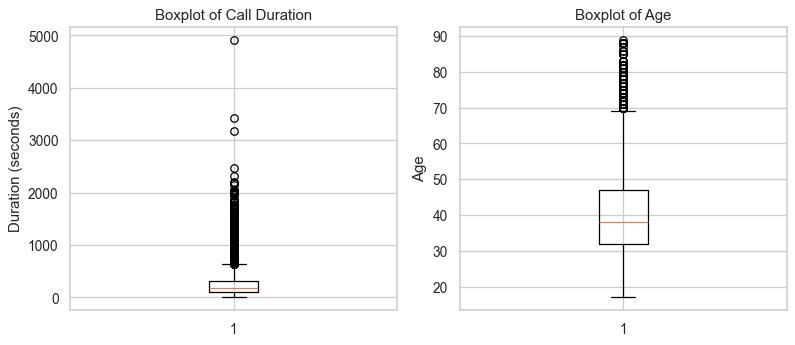

Lower:

 -221.5 Upper: 638.5 | Outliers: 559
Shape after removing outliers: (7676, 21)


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))                            # 14
ax[0].boxplot(bank["duration"]); ax[0].set(title="Boxplot of Call Duration", ylabel="Duration (seconds)")
ax[1].boxplot(bank["age"]);      ax[1].set(title="Boxplot of Age", ylabel="Age")
plt.tight_layout(); plt.show()

Q1, Q3 = bank["duration"].quantile([0.25, 0.75])                        # 15
iqr = Q3 - Q1
lower, upper = Q1 - 1.5 * iqr, Q3 + 1.5 * iqr
outliers = bank[(bank["duration"] < lower) | (bank["duration"] > upper)]
print("Lower:", lower, "Upper:", upper, "| Outliers:", len(outliers))

bank = bank[(bank["duration"] >= lower) & (bank["duration"] <= upper)]  # 16
print("Shape after removing outliers:", bank.shape)

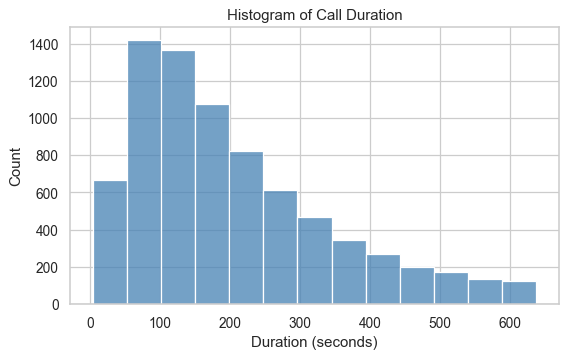

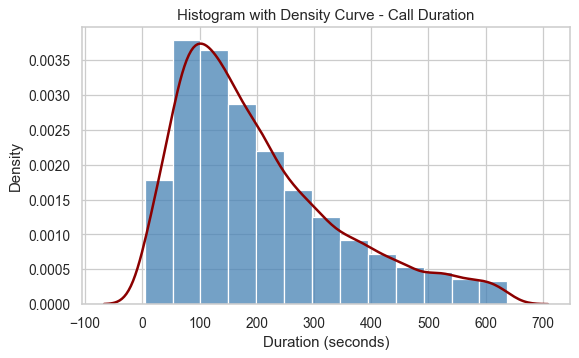

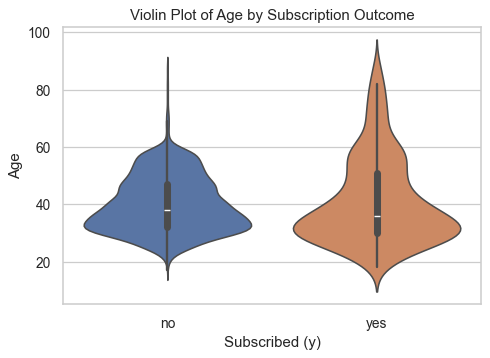

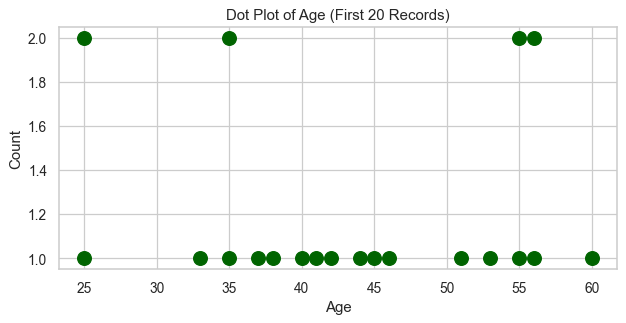

In [15]:
plt.figure(figsize=(7, 4))                                              # 17
sns.histplot(bank["duration"], binwidth=50, color="steelblue", edgecolor="white")
plt.title("Histogram of Call Duration"); plt.xlabel("Duration (seconds)"); plt.ylabel("Count"); plt.show()
# Interpretation: right-skewed (positively skewed). Most calls are short, with a long tail of fewer, much longer calls.

plt.figure(figsize=(7, 4))                                              # 18
sns.histplot(bank["duration"], binwidth=50, stat="density", color="steelblue", edgecolor="white")
sns.kdeplot(bank["duration"], color="darkred", linewidth=2)
plt.title("Histogram with Density Curve - Call Duration"); plt.xlabel("Duration (seconds)"); plt.ylabel("Density"); plt.show()

plt.figure(figsize=(6, 4))                                              # 19
sns.violinplot(data=bank, x="y", y="age", hue="y", legend=False)
plt.title("Violin Plot of Age by Subscription Outcome"); plt.xlabel("Subscribed (y)"); plt.ylabel("Age"); plt.show()

small = bank["age"].head(20).value_counts().sort_index()                # 20
plt.figure(figsize=(8, 3.5))
for age, n in small.items():
    plt.scatter([age] * n, range(1, n + 1), color="darkgreen", s=120)
plt.title("Dot Plot of Age (First 20 Records)"); plt.xlabel("Age"); plt.ylabel("Count"); plt.show()

job
admin.           2043
blue-collar      1737
technician       1267
services          701
management        580
retired           302
entrepreneur      262
self-employed     231
housemaid         209
unemployed        188
student           156
Name: count, dtype: int64
job
admin.           0.2662
blue-collar      0.2263
technician       0.1651
services         0.0913
management       0.0756
retired          0.0393
entrepreneur     0.0341
self-employed    0.0301
housemaid        0.0272
unemployed       0.0245
student          0.0203
Name: proportion, dtype: float64
job
admin.           26.62
blue-collar      22.63
technician       16.51
services          9.13
management        7.56
retired           3.93
entrepreneur      3.41
self-employed     3.01
housemaid         2.72
unemployed        2.45
student           2.03
Name: proportion, dtype: float64


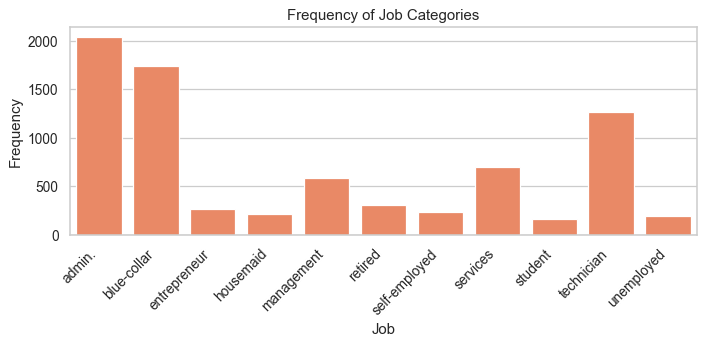

In [16]:
freq_table = bank["job"].value_counts()                                 # 21
print(freq_table)
prop_table = bank["job"].value_counts(normalize=True)                   # 22
print(prop_table.round(4))
print((prop_table * 100).round(2))

plt.figure(figsize=(8, 4))                                              # 23
sns.countplot(data=bank, x="job", color="coral")
plt.title("Frequency of Job Categories"); plt.xlabel("Job"); plt.ylabel("Frequency"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

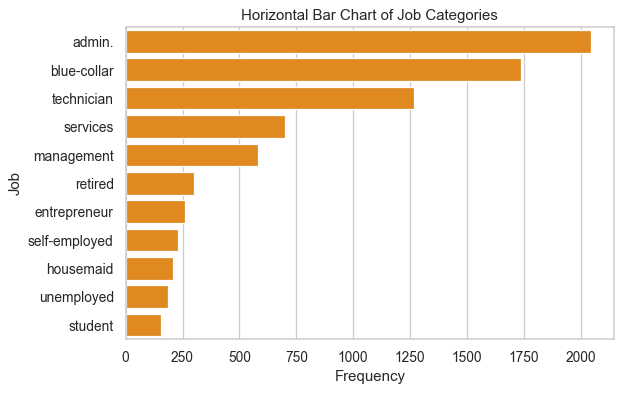

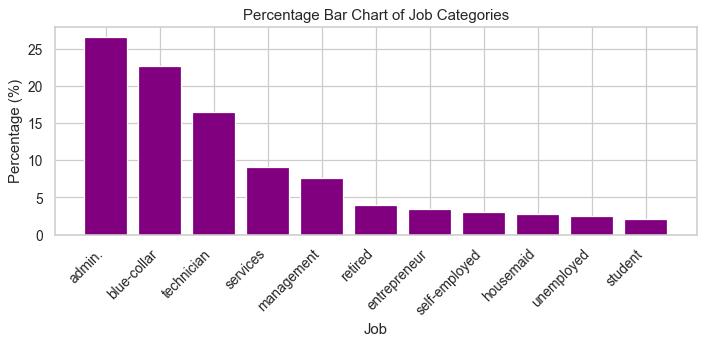

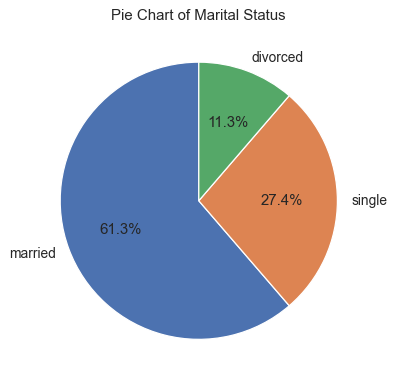

In [17]:
plt.figure(figsize=(7, 4.5))                                            # 24
sns.countplot(data=bank, y="job", order=bank["job"].value_counts().index, color="darkorange")
plt.title("Horizontal Bar Chart of Job Categories"); plt.xlabel("Frequency"); plt.ylabel("Job"); plt.show()

job_pct = bank["job"].value_counts(normalize=True).mul(100)             # 25
plt.figure(figsize=(8, 4))
plt.bar(job_pct.index.astype(str), job_pct.values, color="purple")
plt.title("Percentage Bar Chart of Job Categories"); plt.xlabel("Job"); plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

marital_table = bank["marital"].value_counts()                          # 26
plt.figure(figsize=(5, 5))
plt.pie(marital_table.values, labels=marital_table.index, autopct="%1.1f%%", startangle=90)
plt.title("Pie Chart of Marital Status"); plt.show()

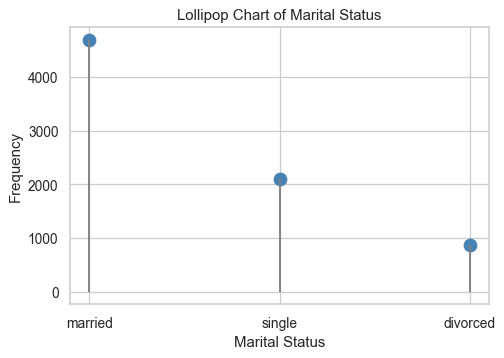

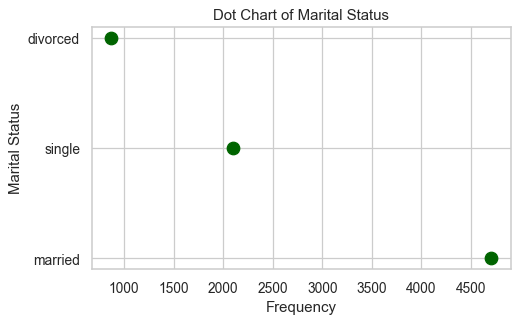

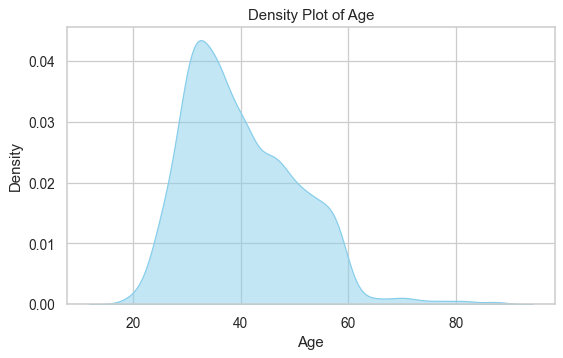

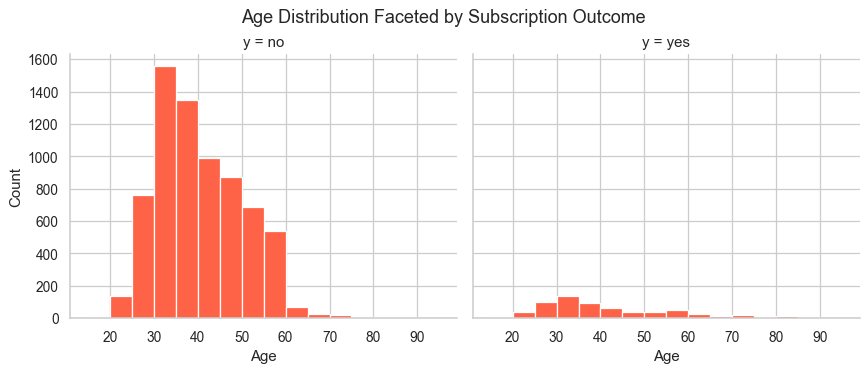

In [18]:
plt.figure(figsize=(6, 4))                                              # 27 lollipop
plt.vlines(marital_table.index, 0, marital_table.values, color="grey")
plt.scatter(marital_table.index, marital_table.values, s=100, color="steelblue")
plt.title("Lollipop Chart of Marital Status"); plt.xlabel("Marital Status"); plt.ylabel("Frequency"); plt.show()

plt.figure(figsize=(6, 3.5))                                            # 28 dot chart
plt.scatter(marital_table.values, marital_table.index, s=100, color="darkgreen")
plt.title("Dot Chart of Marital Status"); plt.xlabel("Frequency"); plt.ylabel("Marital Status"); plt.show()

plt.figure(figsize=(7, 4))                                              # 29
sns.kdeplot(bank["age"], fill=True, color="skyblue", alpha=0.5)
plt.title("Density Plot of Age"); plt.xlabel("Age"); plt.ylabel("Density"); plt.show()

g = sns.FacetGrid(bank, col="y", height=4, aspect=1.2)                  # 30
g.map(plt.hist, "age", bins=range(15, 100, 5), color="tomato", edgecolor="white")
g.set_axis_labels("Age", "Count"); g.figure.suptitle("Age Distribution Faceted by Subscription Outcome", y=1.03); plt.show()

# Assignment 4 – Bivariate Analysis

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8235 entries, 0 to 8234
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             8235 non-null   int64   
 1   job             8235 non-null   category
 2   marital         8235 non-null   category
 3   education       8235 non-null   category
 4   default         8235 non-null   category
 5   housing         8235 non-null   category
 6   loan            8235 non-null   category
 7   contact         8235 non-null   category
 8   month           8235 non-null   category
 9   day_of_week     8235 non-null   category
 10  duration        8235 non-null   int64   
 11  campaign        8235 non-null   int64   
 12  pdays           8235 non-null   int64   
 13  previous        8235 non-null   int64   
 14  poutcome        8235 non-null   category
 15  emp.var.rate    8235 non-null   float64 
 16  cons.price.idx  8235 non-null   float64 
 17  cons.conf.idx 

housing,no,yes
marital,,
divorced,405,526
married,2406,2650
single,962,1286


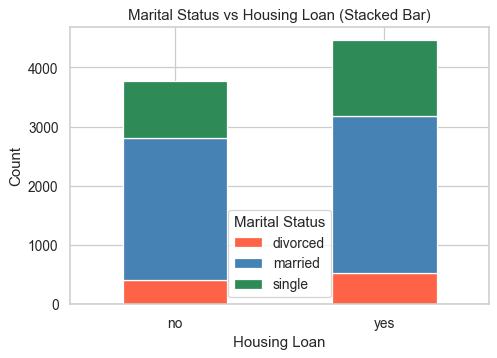

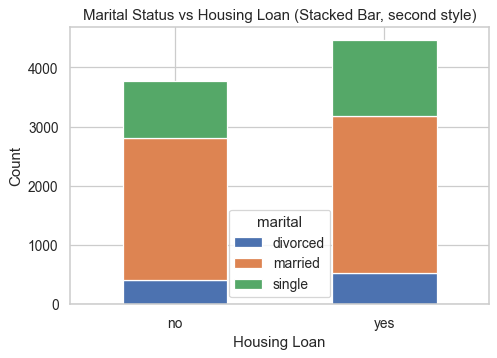

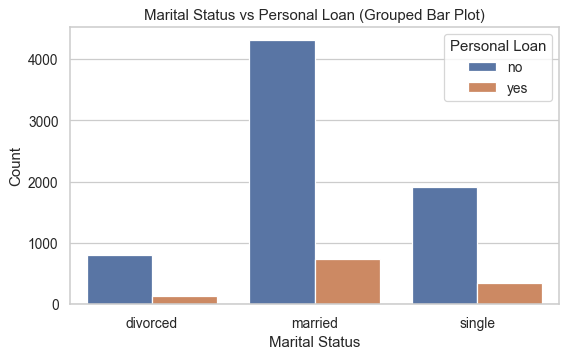

In [19]:
bank = load_clean_bank()                                                # 1
bank.info()

cont_table = pd.crosstab(bank["marital"], bank["housing"])              # 2
display(cont_table)

cont_table.T.plot(kind="bar", stacked=True, color=["tomato","steelblue","seagreen"], figsize=(6, 4), rot=0)   # 2a
plt.title("Marital Status vs Housing Loan (Stacked Bar)"); plt.xlabel("Housing Loan"); plt.ylabel("Count")
plt.legend(title="Marital Status"); plt.show()

pd.crosstab(bank["housing"], bank["marital"]).plot(kind="bar", stacked=True, figsize=(6, 4), rot=0)           # 2b
plt.title("Marital Status vs Housing Loan (Stacked Bar, second style)"); plt.xlabel("Housing Loan"); plt.ylabel("Count"); plt.show()

plt.figure(figsize=(7, 4))                                              # 3
sns.countplot(data=bank, x="marital", hue="loan")
plt.title("Marital Status vs Personal Loan (Grouped Bar Plot)"); plt.xlabel("Marital Status"); plt.ylabel("Count")
plt.legend(title="Personal Loan"); plt.show()

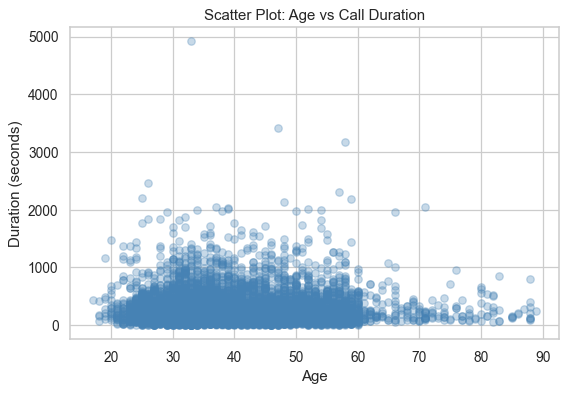

,month,avg_duration
0,mar,245.202020
1,apr,291.704673
2,may,259.876409
3,jun,243.062002
4,jul,267.226782
5,aug,230.251678
6,sep,297.705882
7,oct,308.894366
8,nov,240.708134
9,dec,296.465116


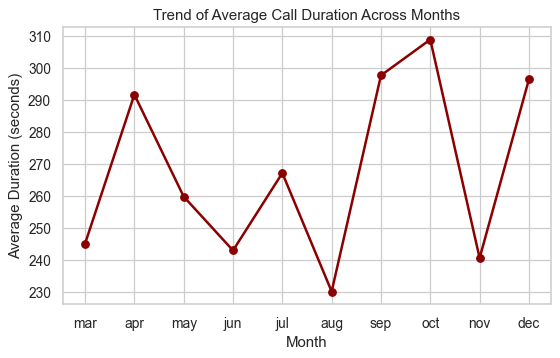

In [20]:
plt.figure(figsize=(7, 4.5))                                            # 4
plt.scatter(bank["age"], bank["duration"], alpha=0.3, color="steelblue")
plt.title("Scatter Plot: Age vs Call Duration"); plt.xlabel("Age"); plt.ylabel("Duration (seconds)"); plt.show()

month_levels = ["mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]   # 5
month_trend = (bank.assign(month=pd.Categorical(bank["month"].astype(str), categories=month_levels, ordered=True))
                   .dropna(subset=["month"]).groupby("month", observed=True)["duration"].mean().reset_index(name="avg_duration"))
display(month_trend)
plt.figure(figsize=(7, 4))
plt.plot(month_trend["month"].astype(str), month_trend["avg_duration"], marker="o", color="darkred", linewidth=2)
plt.title("Trend of Average Call Duration Across Months"); plt.xlabel("Month"); plt.ylabel("Average Duration (seconds)"); plt.show()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.00,-0.00,-0.00,-0.03,0.02,0.01,0.01,0.13,0.02,-0.01
duration,-0.00,1.00,-0.08,-0.04,0.01,-0.02,0.01,-0.01,-0.03,-0.04
campaign,-0.00,-0.08,1.00,0.05,-0.08,0.15,0.13,-0.01,0.14,0.15
pdays,-0.03,-0.04,0.05,1.00,-0.59,0.27,0.08,-0.10,0.30,0.37
previous,0.02,0.01,-0.08,-0.59,1.00,-0.41,-0.20,-0.05,-0.45,-0.50
emp.var.rate,0.01,-0.02,0.15,0.27,-0.41,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.01,0.01,0.13,0.08,-0.20,0.78,1.00,0.06,0.69,0.53
cons.conf.idx,0.13,-0.01,-0.01,-0.10,-0.05,0.20,0.06,1.00,0.28,0.10
euribor3m,0.02,-0.03,0.14,0.30,-0.45,0.97,0.69,0.28,1.00,0.95
nr.employed,-0.01,-0.04,0.15,0.37,-0.50,0.91,0.53,0.10,0.95,1.00


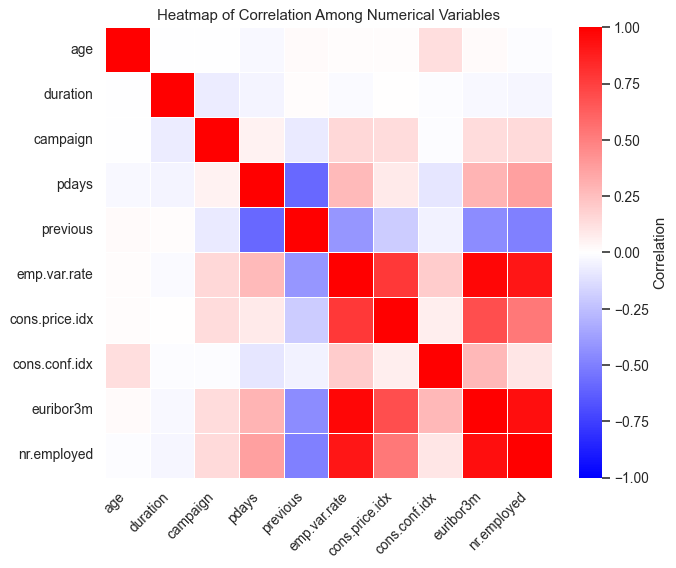

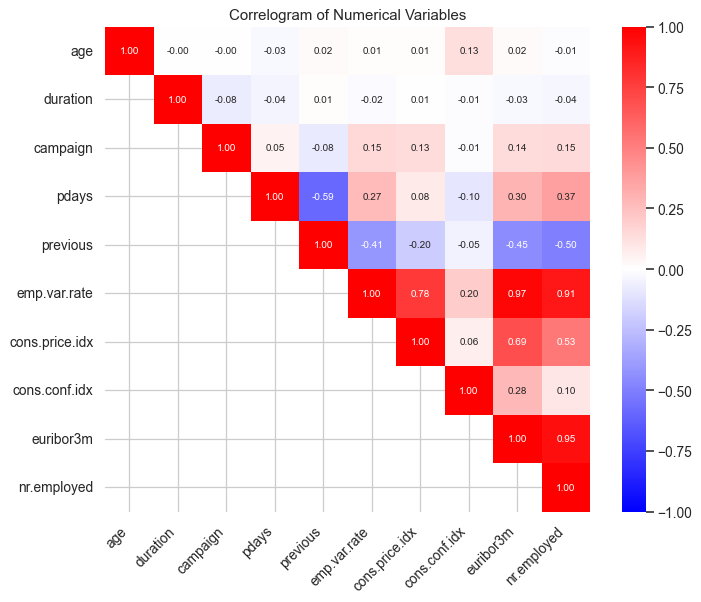

In [21]:
num_vars = bank[["age","duration","campaign","pdays","previous","emp.var.rate",
                 "cons.price.idx","cons.conf.idx","euribor3m","nr.employed"]]
corr_matrix = num_vars.corr()
display(corr_matrix.round(2))

plt.figure(figsize=(8, 6.5))                                            # 6 heatmap
sns.heatmap(corr_matrix, cmap="bwr", vmin=-1, vmax=1, center=0, linewidths=0.5, linecolor="white", cbar_kws={"label": "Correlation"})
plt.title("Heatmap of Correlation Among Numerical Variables"); plt.xticks(rotation=45, ha="right"); plt.show()

mask = np.tril(np.ones_like(corr_matrix, dtype=bool), k=-1)             # 12 correlogram (upper triangle)
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, mask=mask, cmap="bwr", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 8}, square=True)
plt.title("Correlogram of Numerical Variables"); plt.xticks(rotation=45, ha="right"); plt.show()

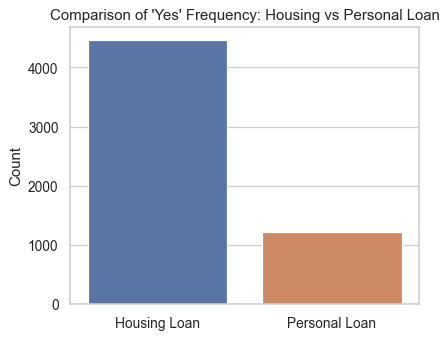

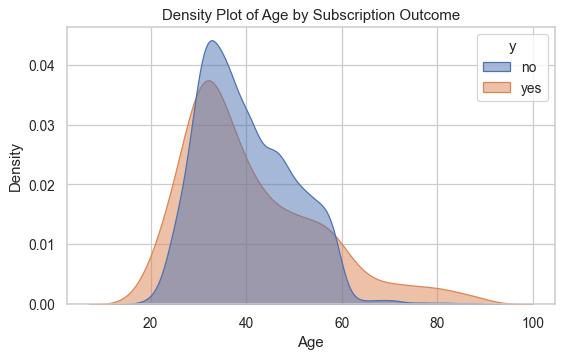

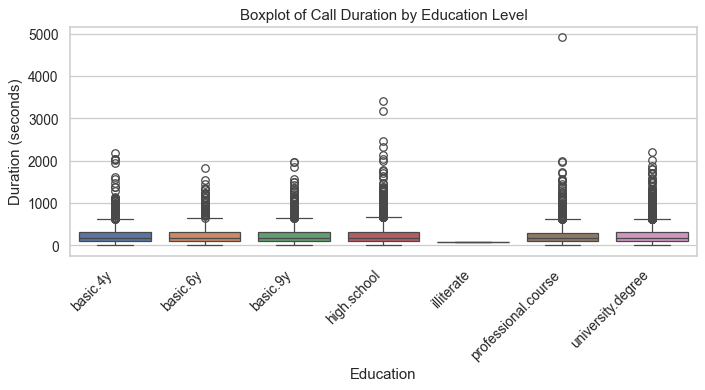

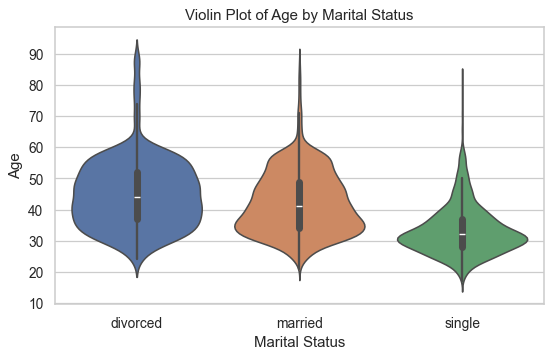

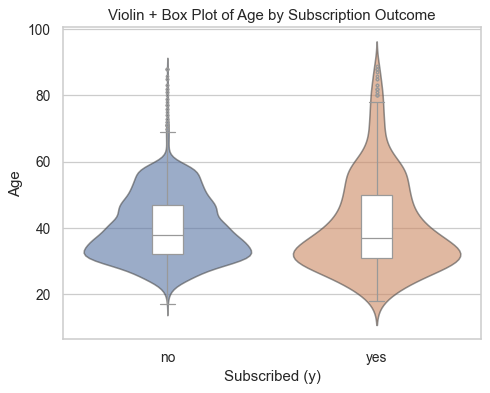

In [22]:
yes_counts = pd.DataFrame({"Variable": ["Housing Loan", "Personal Loan"],     # 7
                           "Yes_Count": [(bank["housing"] == "yes").sum(), (bank["loan"] == "yes").sum()]})
plt.figure(figsize=(5, 4))
sns.barplot(data=yes_counts, x="Variable", y="Yes_Count", hue="Variable", legend=False)
plt.title("Comparison of 'Yes' Frequency: Housing vs Personal Loan"); plt.xlabel(""); plt.ylabel("Count"); plt.show()

plt.figure(figsize=(7, 4))                                              # 8
sns.kdeplot(data=bank, x="age", hue="y", fill=True, alpha=0.5, common_norm=False)
plt.title("Density Plot of Age by Subscription Outcome"); plt.xlabel("Age"); plt.ylabel("Density"); plt.show()

plt.figure(figsize=(8, 4.5))                                            # 9
sns.boxplot(data=bank, x="education", y="duration", hue="education", legend=False)
plt.title("Boxplot of Call Duration by Education Level"); plt.xlabel("Education"); plt.ylabel("Duration (seconds)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))                                              # 10
sns.violinplot(data=bank, x="marital", y="age", hue="marital", legend=False)
plt.title("Violin Plot of Age by Marital Status"); plt.xlabel("Marital Status"); plt.ylabel("Age"); plt.show()

plt.figure(figsize=(6, 4.5))                                            # 11
sns.violinplot(data=bank, x="y", y="age", hue="y", alpha=0.6, inner=None)
sns.boxplot(data=bank, x="y", y="age", width=0.15, color="white", fliersize=2)
plt.title("Violin + Box Plot of Age by Subscription Outcome"); plt.xlabel("Subscribed (y)"); plt.ylabel("Age"); plt.show()

# Assignment 5 – Multivariate Visualisation

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8235 entries, 0 to 8234
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             8235 non-null   int64   
 1   job             8235 non-null   category
 2   marital         8235 non-null   category
 3   education       8235 non-null   category
 4   default         8235 non-null   category
 5   housing         8235 non-null   category
 6   loan            8235 non-null   category
 7   contact         8235 non-null   category
 8   month           8235 non-null   category
 9   day_of_week     8235 non-null   category
 10  duration        8235 non-null   int64   
 11  campaign        8235 non-null   int64   
 12  pdays           8235 non-null   int64   
 13  previous        8235 non-null   int64   
 14  poutcome        8235 non-null   category
 15  emp.var.rate    8235 non-null   float64 
 16  cons.price.idx  8235 non-null   float64 
 17  cons.conf.idx 

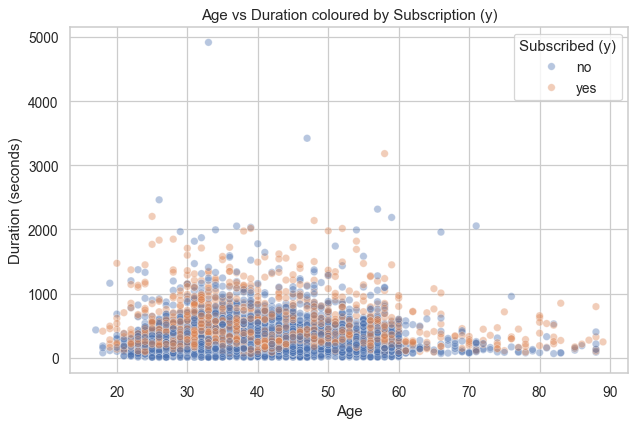

In [23]:
bank = load_clean_bank()                                                # 1
bank.info()
num_var_names = bank.select_dtypes("number").columns.tolist()
cat_var_names = bank.select_dtypes("category").columns.tolist()
print("Numerical:", num_var_names); print("Categorical:", cat_var_names)

plt.figure(figsize=(8, 5))                                              # 2
sns.scatterplot(data=bank, x="age", y="duration", hue="y", alpha=0.4)
plt.title("Age vs Duration coloured by Subscription (y)"); plt.xlabel("Age"); plt.ylabel("Duration (seconds)")
plt.legend(title="Subscribed (y)"); plt.show()

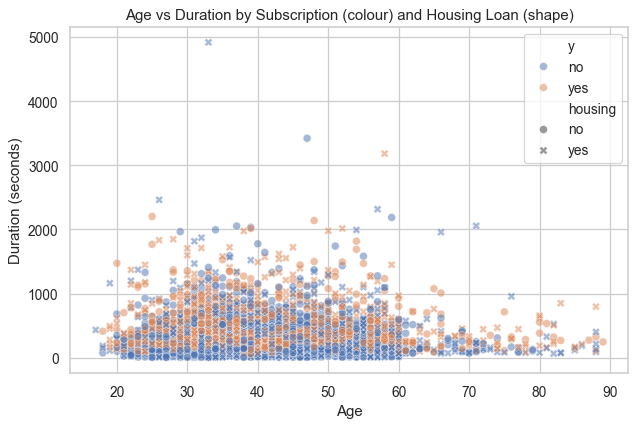

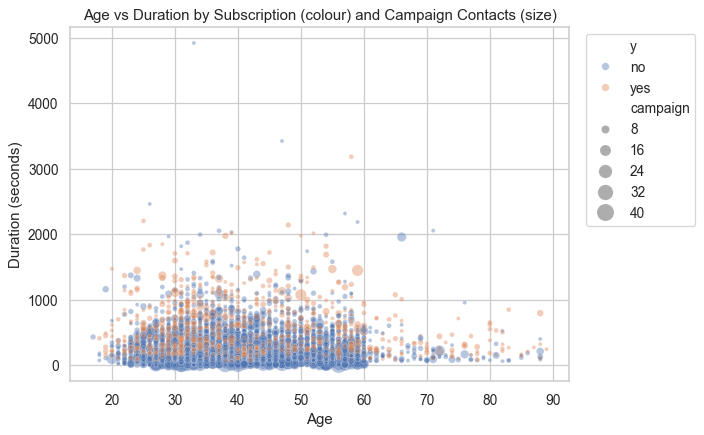

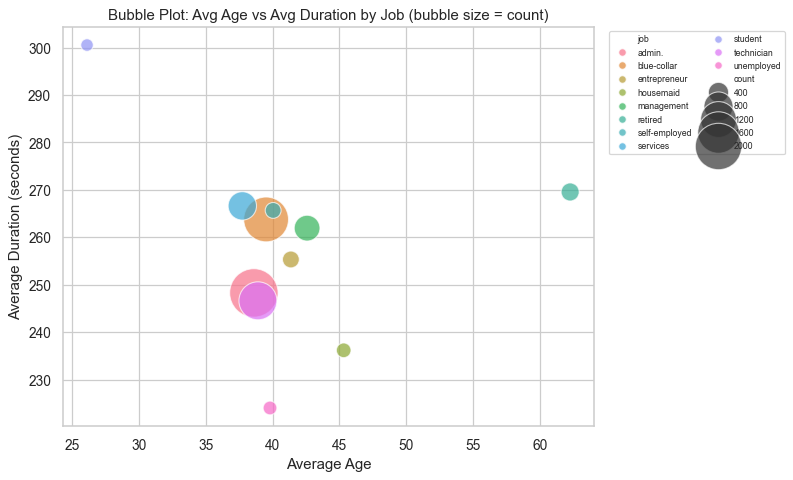

In [24]:
plt.figure(figsize=(8, 5))                                              # 3
sns.scatterplot(data=bank, x="age", y="duration", hue="y", style="housing", alpha=0.5, s=40)
plt.title("Age vs Duration by Subscription (colour) and Housing Loan (shape)"); plt.xlabel("Age"); plt.ylabel("Duration (seconds)"); plt.show()

plt.figure(figsize=(8, 5))                                              # 4
sns.scatterplot(data=bank, x="age", y="duration", hue="y", size="campaign", sizes=(10, 200), alpha=0.4)
plt.title("Age vs Duration by Subscription (colour) and Campaign Contacts (size)"); plt.xlabel("Age"); plt.ylabel("Duration (seconds)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

bubble = bank.groupby("job", observed=True).agg(avg_age=("age","mean"), avg_duration=("duration","mean"), count=("age","size")).reset_index()   # 5
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=bubble, x="avg_age", y="avg_duration", size="count", hue="job", sizes=(100, 1500), alpha=0.7)
plt.title("Bubble Plot: Avg Age vs Avg Duration by Job (bubble size = count)"); plt.xlabel("Average Age"); plt.ylabel("Average Duration (seconds)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=7); plt.tight_layout(); plt.show()

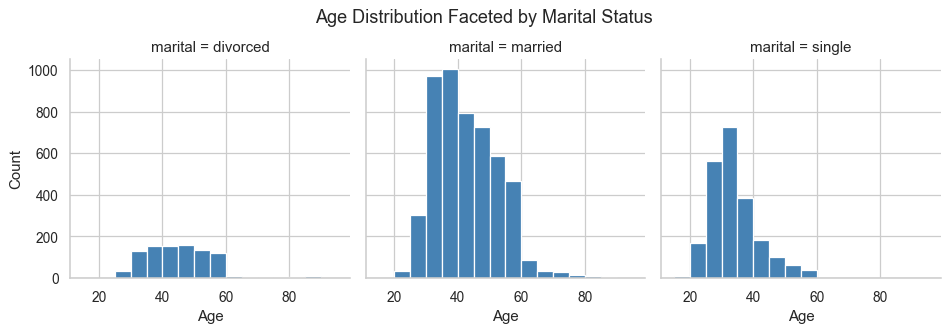

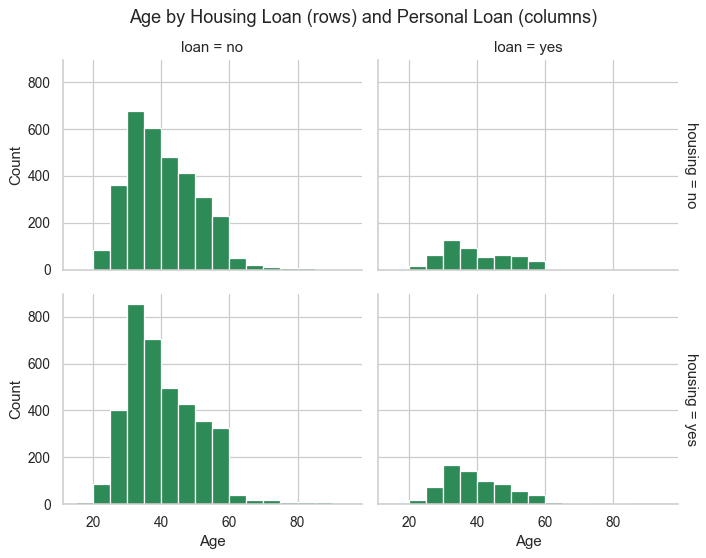

In [25]:
g = sns.FacetGrid(bank, col="marital", height=3.5)                      # 6
g.map(plt.hist, "age", bins=range(15, 100, 5), color="steelblue", edgecolor="white")
g.set_axis_labels("Age", "Count"); g.figure.suptitle("Age Distribution Faceted by Marital Status", y=1.05); plt.show()

g = sns.FacetGrid(bank, row="housing", col="loan", height=3, aspect=1.3, margin_titles=True)   # 7
g.map(plt.hist, "age", bins=range(15, 100, 5), color="seagreen", edgecolor="white")
g.set_axis_labels("Age", "Count"); g.figure.suptitle("Age by Housing Loan (rows) and Personal Loan (columns)", y=1.03); plt.show()

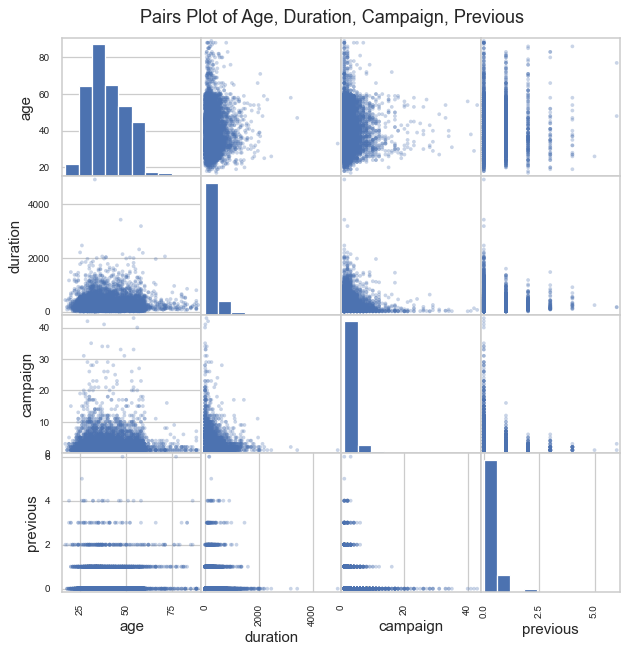

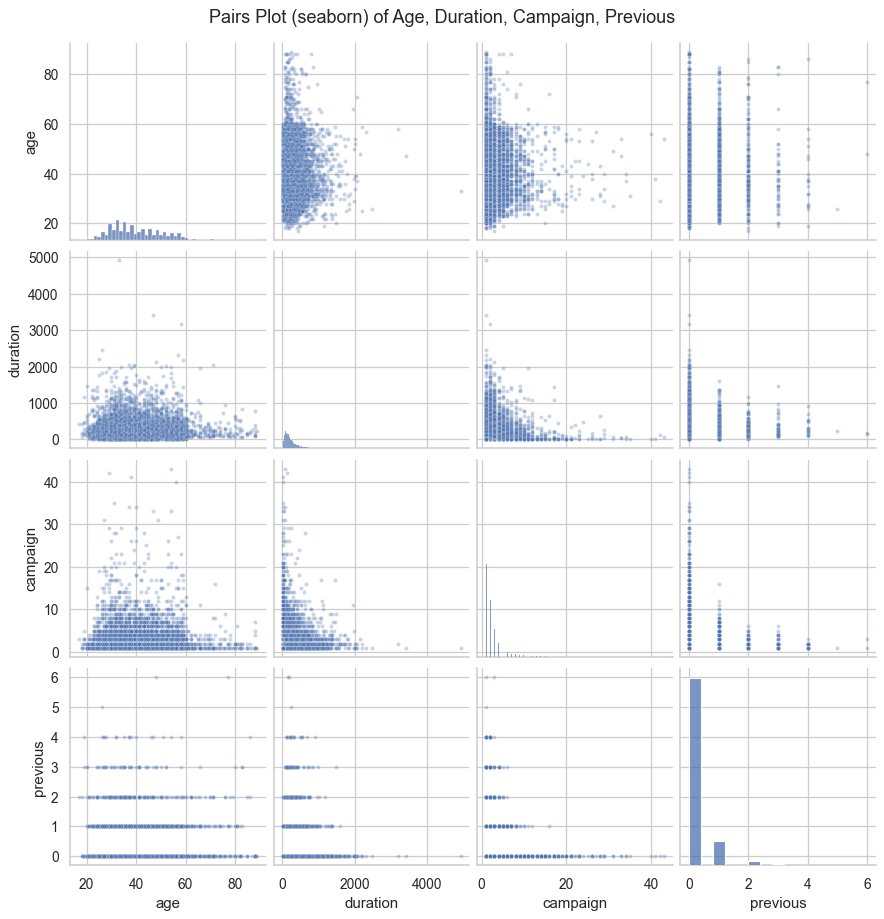

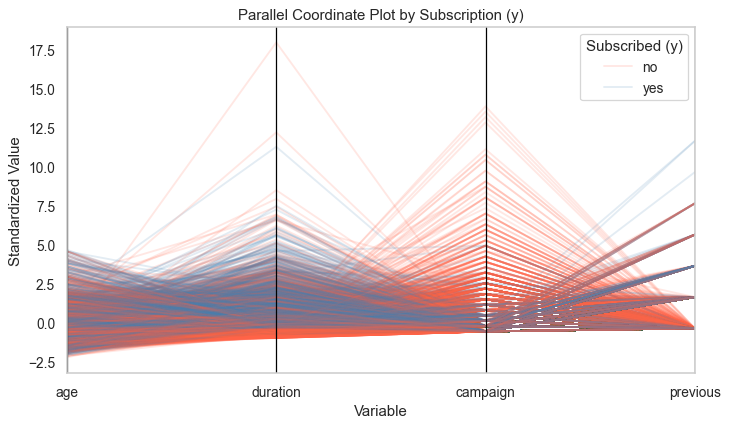

In [26]:
pv = ["age", "duration", "campaign", "previous"]
pd.plotting.scatter_matrix(bank[pv], figsize=(8, 8), alpha=0.3, diagonal="hist")      # 8 base style
plt.suptitle("Pairs Plot of Age, Duration, Campaign, Previous", y=0.92); plt.show()

sns.pairplot(bank[pv], corner=False, plot_kws={"alpha": 0.3, "s": 10})                # 8 ggpairs style
plt.suptitle("Pairs Plot (seaborn) of Age, Duration, Campaign, Previous", y=1.02); plt.show()

std = (bank[pv] - bank[pv].mean()) / bank[pv].std()                                   # 9
std["y"] = bank["y"].astype(str).values
plt.figure(figsize=(9, 5))
pd.plotting.parallel_coordinates(std, "y", color=("tomato", "steelblue"), alpha=0.15)
plt.title("Parallel Coordinate Plot by Subscription (y)"); plt.xlabel("Variable"); plt.ylabel("Standardized Value")
plt.legend(title="Subscribed (y)"); plt.show()

# Assignment 6 – Time Series Analysis (AirPassengers)

In [27]:
raw = sm.datasets.get_rdataset("AirPassengers").data                     # 1
airdata = pd.Series(raw["value"].values, index=pd.date_range("1949-01-01", periods=len(raw), freq="MS"), name="Passengers")
print(airdata.head(5)); print(airdata.tail(5))                          # 2
print("Start:", airdata.index[0].strftime("%Y-%m"), "| End:", airdata.index[-1].strftime("%Y-%m"))   # 3
print("Frequency:", 12, "(monthly) | pandas freq:", airdata.index.freq, "| class:", type(airdata).__name__)   # 4
print("First time point: 1949.0 | Last time point: %.4f" % (1960 + 11 / 12))

1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64
1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, dtype: int64
Start: 1949-01 | End: 1960-12
Frequency: 12 (monthly) | pandas freq: <MonthBegin> | class: Series
First time point: 1949.0 | Last time point: 1960.9167


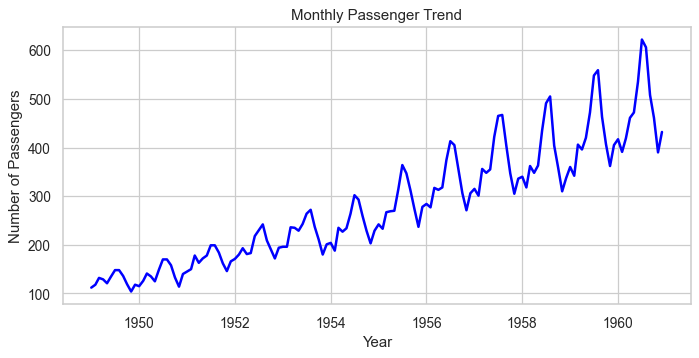

,trend,seasonal,random
1949-01-01,NaN,-24.748737,NaN
1949-02-01,NaN,-36.188131,NaN
1949-03-01,NaN,-2.241162,NaN
1949-04-01,NaN,-8.036616,NaN
1949-05-01,NaN,-4.506313,NaN
1949-06-01,NaN,35.402778,NaN
1949-07-01,126.791667,63.830808,-42.622475
1949-08-01,127.250000,62.823232,-42.073232
1949-09-01,127.958333,16.520202,-8.478535
1949-10-01,128.583333,-20.642677,11.059343


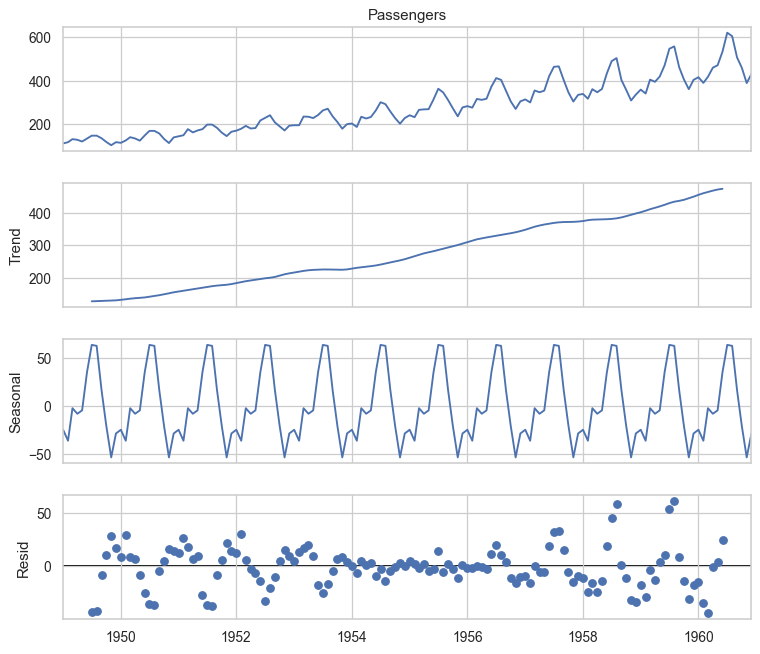

In [28]:
plt.figure(figsize=(9, 4))                                              # 5
plt.plot(airdata, color="blue", linewidth=2)
plt.title("Monthly Passenger Trend"); plt.xlabel("Year"); plt.ylabel("Number of Passengers"); plt.show()

decomposed = seasonal_decompose(airdata, model="additive", period=12)   # 6
display(pd.DataFrame({"trend": decomposed.trend, "seasonal": decomposed.seasonal, "random": decomposed.resid}).head(14))
fig = decomposed.plot(); fig.set_size_inches(9, 8); plt.show()          # 7

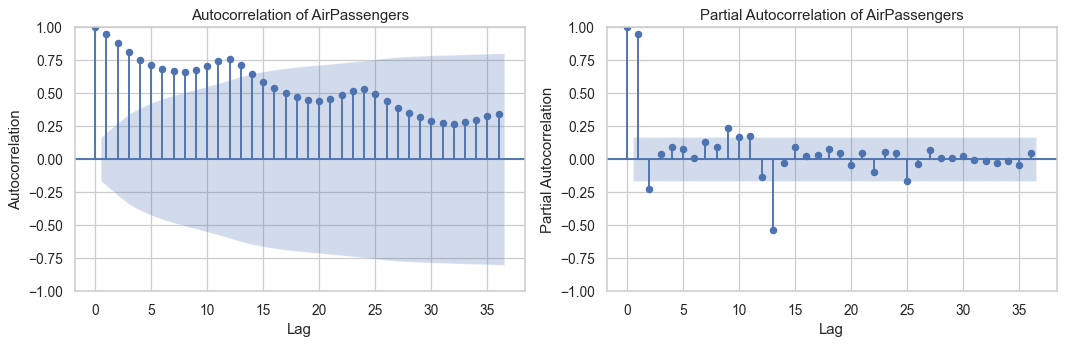

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))                           # 8
plot_acf(airdata, lags=36, ax=ax[0], title="Autocorrelation of AirPassengers"); ax[0].set(xlabel="Lag", ylabel="Autocorrelation")
plot_pacf(airdata, lags=36, ax=ax[1], title="Partial Autocorrelation of AirPassengers"); ax[1].set(xlabel="Lag", ylabel="Partial Autocorrelation")
plt.tight_layout(); plt.show()

In [30]:
arima_model = ARIMA(airdata, order=(1, 1, 1)).fit()                     # 9
print(arima_model.summary())                                            # 10

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -694.341
Date:                Mon, 19 Oct 2026   AIC                           1394.683
Time:                        16:31:43   BIC                           1403.571
Sample:                    01-01-1949   HQIC                          1398.294
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4742      0.123     -3.847      0.000      -0.716      -0.233
ma.L1          0.8635      0.078     11.051      0.000       0.710       1.017
sigma2       961.9270    107.433      8.954      0.0

,pred,se
1961-01-01,475.735059,31.014948
1961-02-01,454.996073,53.090451
1961-03-01,464.830415,64.920204
1961-04-01,460.167010,76.294994
1961-05-01,462.378378,85.590179
1961-06-01,461.329756,94.224032
1961-07-01,461.827008,102.019254
1961-08-01,461.591213,109.308945
1961-09-01,461.703026,116.120011
1961-10-01,461.650005,122.562998


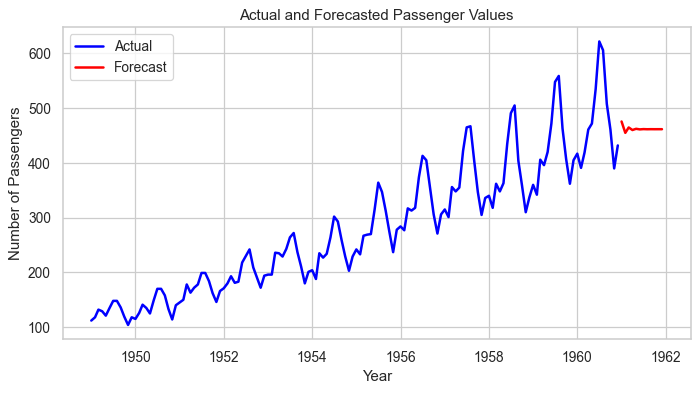

In [31]:
forecast = arima_model.get_forecast(steps=12)                           # 11
forecast_values = forecast.predicted_mean
display(pd.DataFrame({"pred": forecast_values, "se": forecast.se_mean}))

plt.figure(figsize=(9, 4.5))                                            # 12
plt.plot(airdata, color="blue", linewidth=2, label="Actual")
plt.plot(forecast_values, color="red", linewidth=2, label="Forecast")
plt.title("Actual and Forecasted Passenger Values"); plt.xlabel("Year"); plt.ylabel("Number of Passengers")
plt.legend(loc="upper left"); plt.show()

# Assignment 7 – 1D, 2D and N-D Analysis

In [32]:
bank = load_clean_bank()                                                # 1
bank.info()

x = bank["duration"].values; n = len(x)
skew = stats.skew(x, bias=True) * ((n - 1) / n) ** 1.5                  # e1071 type 3
kurt = (stats.kurtosis(x, fisher=True, bias=True) + 3) * (1 - 1 / n) ** 2 - 3
summary_stats = pd.DataFrame({"Statistic": ["Mean","Median","Minimum","Maximum","Range","Variance","StdDev","IQR","Skewness","Kurtosis"],
    "Value": [x.mean(), np.median(x), x.min(), x.max(), x.max() - x.min(), x.var(ddof=1), x.std(ddof=1),
              np.percentile(x, 75) - np.percentile(x, 25), skew, kurt]})
print(summary_stats)                                                    # 2, 3

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8235 entries, 0 to 8234
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             8235 non-null   int64   
 1   job             8235 non-null   category
 2   marital         8235 non-null   category
 3   education       8235 non-null   category
 4   default         8235 non-null   category
 5   housing         8235 non-null   category
 6   loan            8235 non-null   category
 7   contact         8235 non-null   category
 8   month           8235 non-null   category
 9   day_of_week     8235 non-null   category
 10  duration        8235 non-null   int64   
 11  campaign        8235 non-null   int64   
 12  pdays           8235 non-null   int64   
 13  previous        8235 non-null   int64   
 14  poutcome        8235 non-null   category
 15  emp.var.rate    8235 non-null   float64 
 16  cons.price.idx  8235 non-null   float64 
 17  cons.conf.idx 

  Statistic         Value
0      Mean    256.051245
1    Median    179.000000
2   Minimum      4.000000
3   Maximum   4918.000000
4     Range   4914.000000
5  Variance  67467.113963
6    StdDev    259.744324
7       IQR    215.000000
8  Skewness      3.554827
9  Kurtosis     26.491196


job
admin.           2175
blue-collar      1866
technician       1347
services          763
management        633
retired           324
entrepreneur      284
self-employed     255
housemaid         222
unemployed        198
student           168
Name: count, dtype: int64
job
admin.           0.2641
blue-collar      0.2266
technician       0.1636
services         0.0927
management       0.0769
retired          0.0393
entrepreneur     0.0345
self-employed    0.0310
housemaid        0.0270
unemployed       0.0240
student          0.0204
Name: proportion, dtype: float64


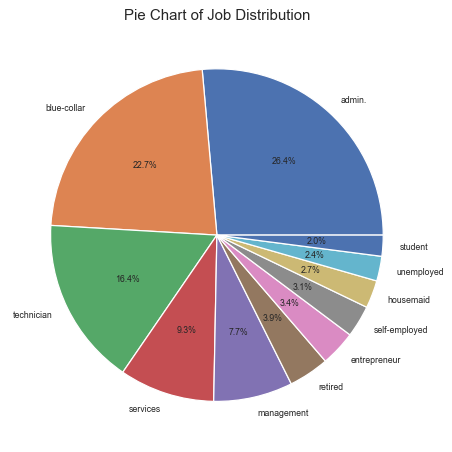

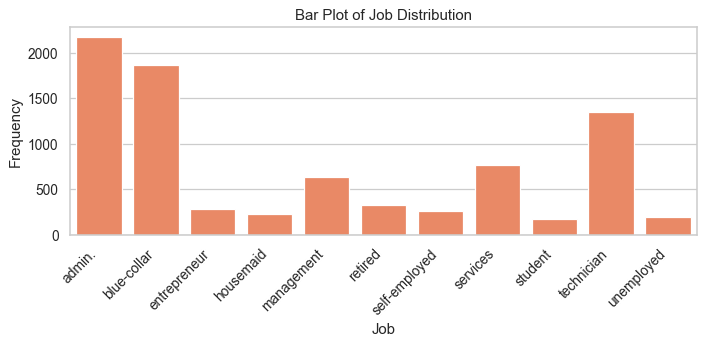

duration_bin
(0, 200]        4556
(200, 400]      2261
(400, 600]       764
(600, 800]       319
(800, 1000]      148
(1000, 1200]      82
(1200, 1400]      49
(1400, 1600]      22
(1600, 1800]      10
(1800, 2000]      11
(2000, 2200]       7
(2200, 2400]       2
(2400, 2600]       1
(2600, 2800]       0
(2800, 3000]       0
(3000, 3200]       1
(3200, 3400]       0
(3400, 3600]       1
(3600, 3800]       0
(3800, 4000]       0
(4000, 4200]       0
(4200, 4400]       0
(4400, 4600]       0
(4600, 4800]       0
(4800, 5000]       1
Name: count, dtype: int64


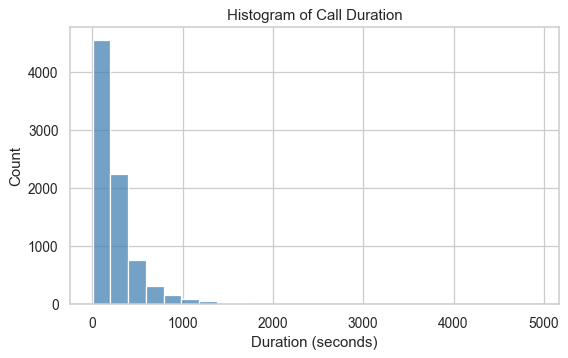

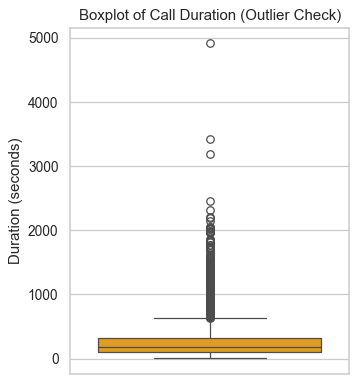

In [33]:
job_freq = bank["job"].value_counts()                                   # 4
print(job_freq); print(bank["job"].value_counts(normalize=True).round(4))
plt.figure(figsize=(6, 6)); plt.pie(job_freq.values, labels=job_freq.index, autopct="%1.1f%%", textprops={"fontsize": 7})
plt.title("Pie Chart of Job Distribution"); plt.show()
plt.figure(figsize=(8, 4)); sns.countplot(data=bank, x="job", color="coral")
plt.title("Bar Plot of Job Distribution"); plt.xlabel("Job"); plt.ylabel("Frequency"); plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

bin_width = 200                                                         # 5
bins = np.arange(0, bank["duration"].max() + bin_width + 1, bin_width)
bank["duration_bin"] = pd.cut(bank["duration"], bins=bins)
print(bank["duration_bin"].value_counts().sort_index())
plt.figure(figsize=(7, 4)); sns.histplot(bank["duration"], binwidth=bin_width, color="steelblue", edgecolor="white")
plt.title("Histogram of Call Duration"); plt.xlabel("Duration (seconds)"); plt.ylabel("Count"); plt.show()
plt.figure(figsize=(4, 5)); sns.boxplot(y=bank["duration"], color="orange")
plt.title("Boxplot of Call Duration (Outlier Check)"); plt.ylabel("Duration (seconds)"); plt.show()

housing,no,yes
marital,,
divorced,405,526
married,2406,2650
single,962,1286


housing,no,yes
marital,,
divorced,43.50,56.50
married,47.59,52.41
single,42.79,57.21


housing,no,yes
marital,,
divorced,10.73,11.79
married,63.77,59.39
single,25.50,28.82


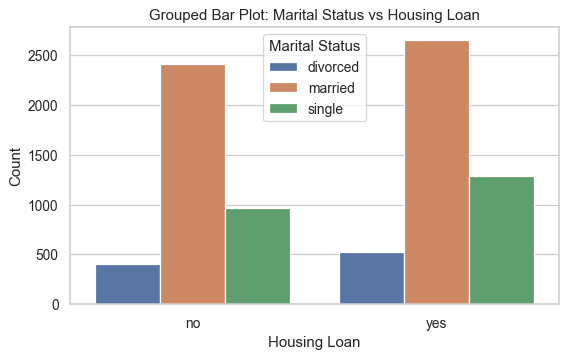

,education,mean,median,std
0,basic.4y,261.719706,181.0,270.066134
1,basic.6y,262.348786,173.0,268.911740
2,basic.9y,255.964638,186.5,239.868578
3,high.school,265.244119,181.0,278.982381
4,illiterate,89.500000,89.5,3.535534
5,professional.course,252.373786,178.0,285.292360
6,university.degree,248.617689,175.0,239.231170


In [34]:
cont_table = pd.crosstab(bank["marital"], bank["housing"])              # 6
display(cont_table)
display((pd.crosstab(bank["marital"], bank["housing"], normalize="index") * 100).round(2))   # row %
display((pd.crosstab(bank["marital"], bank["housing"], normalize="columns") * 100).round(2)) # column %

plt.figure(figsize=(7, 4)); sns.countplot(data=bank, x="housing", hue="marital")                # 7
plt.title("Grouped Bar Plot: Marital Status vs Housing Loan"); plt.xlabel("Housing Loan"); plt.ylabel("Count"); plt.legend(title="Marital Status"); plt.show()

agg_stats = bank.groupby("education", observed=True)["duration"].agg(["mean","median","std"]).reset_index()   # 8
display(agg_stats)

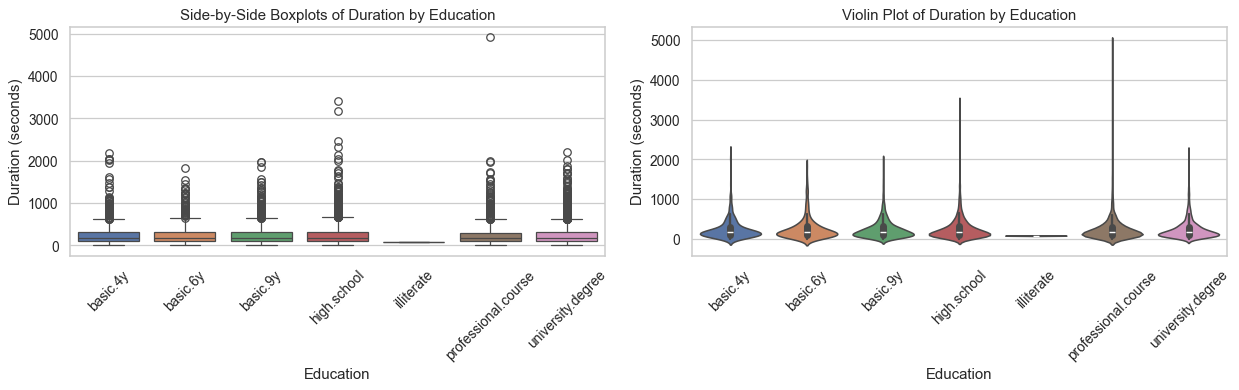

Pearson : -0.0011320545393340084
Spearman: -0.014387132484695466


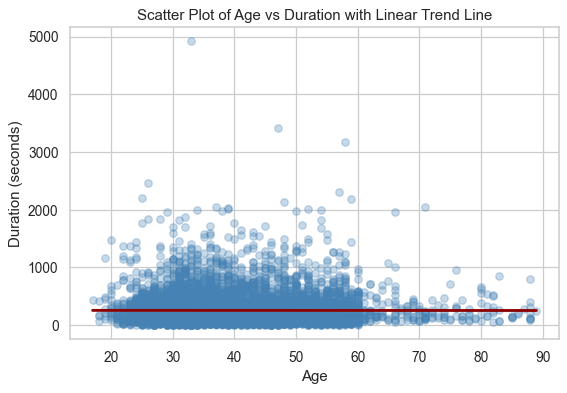

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))                         # 9
sns.boxplot(data=bank, x="education", y="duration", hue="education", legend=False, ax=ax[0])
ax[0].set(title="Side-by-Side Boxplots of Duration by Education", xlabel="Education", ylabel="Duration (seconds)"); ax[0].tick_params(axis="x", rotation=45)
sns.violinplot(data=bank, x="education", y="duration", hue="education", legend=False, ax=ax[1])
ax[1].set(title="Violin Plot of Duration by Education", xlabel="Education", ylabel="Duration (seconds)"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

print("Pearson :", bank["age"].corr(bank["duration"], method="pearson"))      # 10
print("Spearman:", bank["age"].corr(bank["duration"], method="spearman"))
plt.figure(figsize=(7, 4.5))
sns.regplot(data=bank, x="age", y="duration", scatter_kws={"alpha": 0.3, "color": "steelblue"}, line_kws={"color": "darkred"})
plt.title("Scatter Plot of Age vs Duration with Linear Trend Line"); plt.xlabel("Age"); plt.ylabel("Duration (seconds)"); plt.show()

,marital,housing,mean_duration,sd_duration
0,divorced,no,256.150617,284.274340
1,divorced,yes,250.965779,240.990051
2,married,no,258.412303,257.713468
3,married,yes,251.229057,256.011738
4,single,no,266.276507,247.183558
5,single,yes,255.970451,279.143109


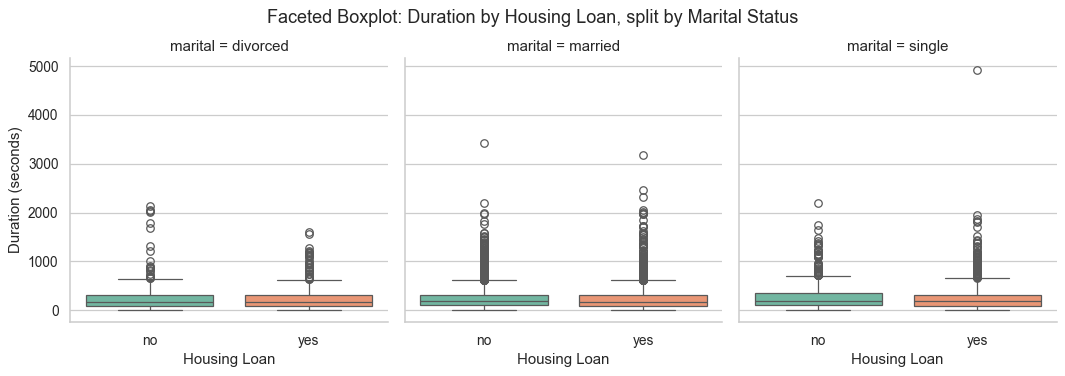

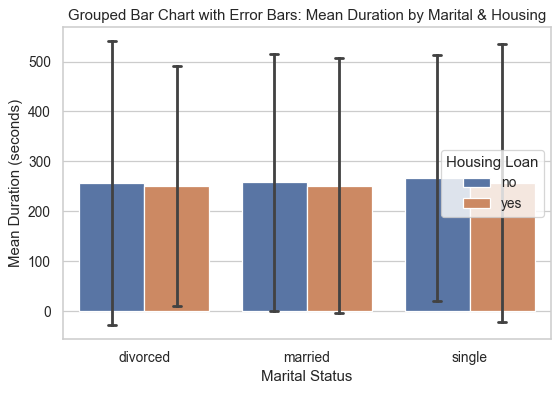

In [36]:
group_stats = (bank.groupby(["marital", "housing"], observed=True)["duration"].agg(mean_duration="mean", sd_duration="std").reset_index())
display(group_stats)

g = sns.FacetGrid(bank, col="marital", height=4)
g.map_dataframe(sns.boxplot, x="housing", y="duration", hue="housing", palette="Set2")
g.set_axis_labels("Housing Loan", "Duration (seconds)"); g.figure.suptitle("Faceted Boxplot: Duration by Housing Loan, split by Marital Status", y=1.04); plt.show()

plt.figure(figsize=(7, 4.5))
sns.barplot(data=bank, x="marital", y="duration", hue="housing", errorbar="sd", capsize=0.1)
plt.title("Grouped Bar Chart with Error Bars: Mean Duration by Marital & Housing")
plt.xlabel("Marital Status"); plt.ylabel("Mean Duration (seconds)"); plt.legend(title="Housing Loan"); plt.show()

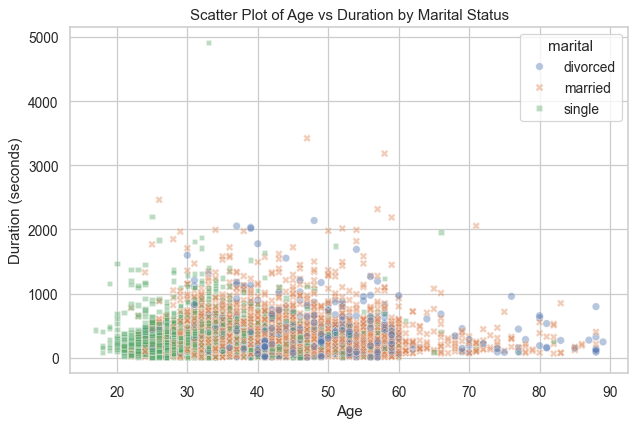

,marital,correlation
0,divorced,0.011318
1,married,0.009429
2,single,-0.018139


,age,duration,campaign,previous
age,1.00,-0.00,-0.00,0.02
duration,-0.00,1.00,-0.08,0.01
campaign,-0.00,-0.08,1.00,-0.08
previous,0.02,0.01,-0.08,1.00


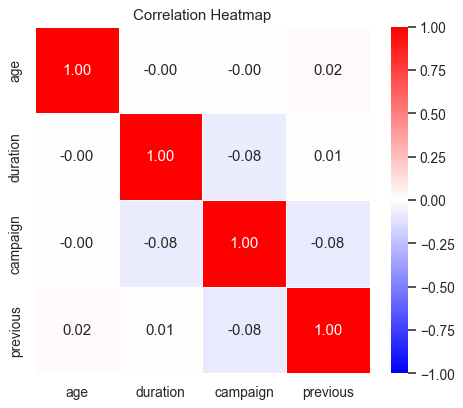

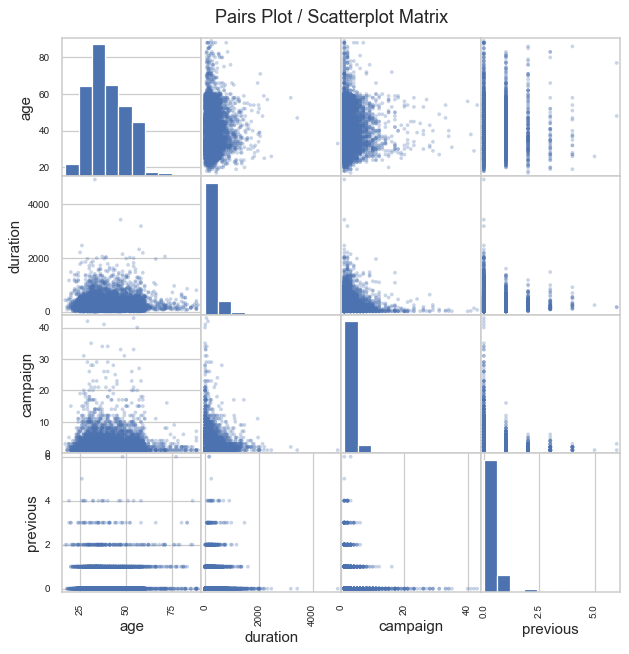

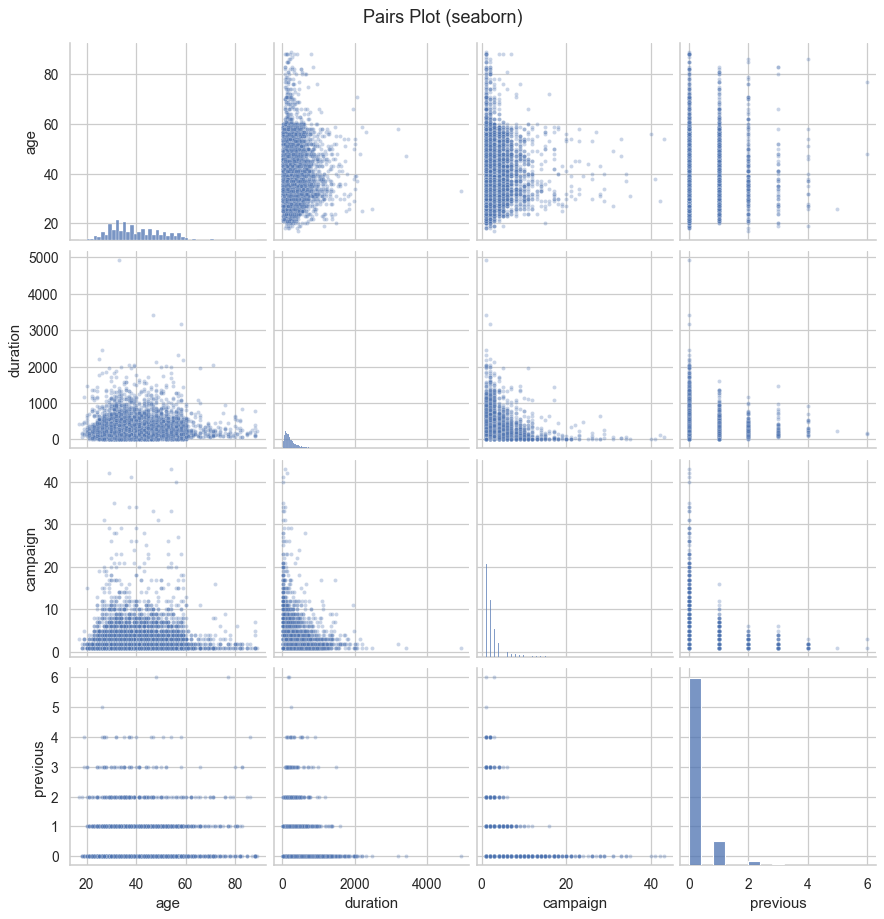

In [37]:
plt.figure(figsize=(8, 5))                                              # 12
sns.scatterplot(data=bank, x="age", y="duration", hue="marital", style="marital", alpha=0.4)
plt.title("Scatter Plot of Age vs Duration by Marital Status"); plt.xlabel("Age"); plt.ylabel("Duration (seconds)"); plt.show()
display(bank.groupby("marital", observed=True).apply(lambda d: d["age"].corr(d["duration"])).reset_index(name="correlation"))

num_vars13 = bank[["age", "duration", "campaign", "previous"]]          # 13
corr13 = num_vars13.corr(); display(corr13.round(2))
plt.figure(figsize=(6, 5)); sns.heatmap(corr13, cmap="bwr", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap"); plt.show()

pd.plotting.scatter_matrix(num_vars13, figsize=(8, 8), alpha=0.3)       # 14
plt.suptitle("Pairs Plot / Scatterplot Matrix", y=0.92); plt.show()
sns.pairplot(num_vars13, plot_kws={"alpha": 0.3, "s": 10}); plt.suptitle("Pairs Plot (seaborn)", y=1.02); plt.show()

# Assignment 8 – K-Means and Hierarchical Clustering

In [38]:
bank = pd.read_csv(CSV)                                                 # 1
display(bank.head()); bank.info()                                       # 2
print("Missing values:", bank.isna().sum().sum()); print(bank.isna().sum())   # 3
print(bank["y"].value_counts())                                         # 4
bank_num = bank.select_dtypes("number"); bank_num.info()                # 5
bank_scaled = (bank_num - bank_num.mean()) / bank_num.std(ddof=1)       # 6
display(bank_scaled.head())

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,35,blue-collar,married,basic.6y,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,46,blue-collar,married,basic.6y,unknown,yes,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8237 entries, 0 to 8236
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             8237 non-null   int64  
 1   job             8237 non-null   object 
 2   marital         8237 non-null   object 
 3   education       8237 non-null   object 
 4   default         8237 non-null   object 
 5   housing         8237 non-null   object 
 6   loan            8237 non-null   object 
 7   contact         8237 non-null   object 
 8   month           8237 non-null   object 
 9   day_of_week     8237 non-null   object 
 10  duration        8237 non-null   int64  
 11  campaign        8237 non-null   int64  
 12  pdays           8237 non-null   int64  
 13  previous        8237 non-null   int64  
 14  poutcome        8237 non-null   object 
 15  emp.var.rate    8237 non-null   float64
 16  cons.price.idx  8237 non-null   float64
 17  cons.conf.idx   8237 non-null   f

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,1.517721,0.196329,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827
1,0.084417,-0.150186,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827
2,-1.444441,-0.130935,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827
3,-0.488905,0.215580,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827
4,0.562185,0.708402,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827


In [39]:
kmeans_result = KMeans(n_clusters=2, n_init=25, random_state=123).fit(bank_scaled)   # 7
print("Cluster sizes:", np.bincount(kmeans_result.labels_))             # 8
print("Total within-cluster SS:", kmeans_result.inertia_)
display(pd.DataFrame(kmeans_result.cluster_centers_, columns=bank_scaled.columns))   # 9

Cluster sizes: [2733 5504]
Total within-cluster SS: 53413.42505915223


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,-0.047218,0.040864,-0.175528,-0.394882,0.599061,-1.336159,-0.938130,-0.460539,-1.399097,-1.301075
1,0.023446,-0.020291,0.087158,0.196078,-0.297463,0.663467,0.465827,0.228680,0.694719,0.646046


[82360.   53413.43 43252.04 38853.47 34717.76 31303.44 28533.77 26883.93
 24858.34 23344.83]


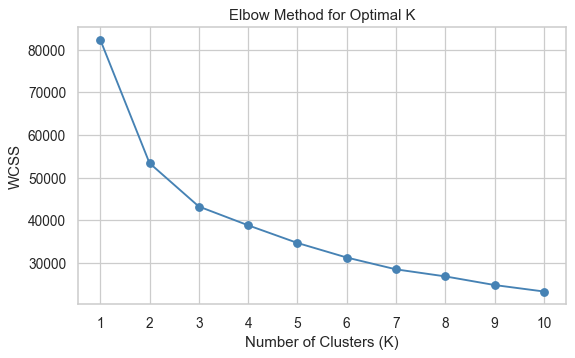

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,-0.070591,0.016668,-0.163363,0.196078,0.277770,-1.331764,-1.009616,-0.587291,-1.383851,-1.221104
1,0.023598,-0.019978,0.087390,0.196078,-0.297444,0.663771,0.466509,0.229184,0.694943,0.646232
2,0.131431,0.222198,-0.272055,-4.963969,3.079161,-1.362727,-0.387995,0.515815,-1.507638,-1.910718


0    2422
1    5502
2     313
Name: count, dtype: int64


In [40]:
wcss = []                                                               # 10
for k in range(1, 11):
    wcss.append(KMeans(n_clusters=k, n_init=10, random_state=123).fit(bank_scaled).inertia_)
print(np.round(wcss, 2))

plt.figure(figsize=(7, 4))                                              # 11
plt.plot(range(1, 11), wcss, marker="o", color="steelblue")
plt.title("Elbow Method for Optimal K"); plt.xlabel("Number of Clusters (K)"); plt.ylabel("WCSS"); plt.xticks(range(1, 11)); plt.show()

kmeans_final = KMeans(n_clusters=3, n_init=25, random_state=123).fit(bank_scaled)   # 12
display(pd.DataFrame(kmeans_final.cluster_centers_, columns=bank_scaled.columns))
print(pd.Series(kmeans_final.labels_).value_counts().sort_index())

In [41]:
bank = pd.read_csv(CSV)
display(bank.head()); print("Missing values:", bank.isna().sum().sum())
bank_num = bank.select_dtypes("number")
bank_scaled = (bank_num - bank_num.mean()) / bank_num.std(ddof=1)
display(bank_scaled.head())

hc = linkage(bank_scaled.values, method="ward", metric="euclidean")     # 6, 7 (Ward with Euclidean distance)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,35,blue-collar,married,basic.6y,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,46,blue-collar,married,basic.6y,unknown,yes,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Missing values: 0


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,1.517721,0.196329,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827
1,0.084417,-0.150186,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827
2,-1.444441,-0.130935,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827
3,-0.488905,0.215580,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827
4,0.562185,0.708402,-0.550384,0.196078,-0.348277,0.654006,0.714941,0.896552,0.71938,0.336827


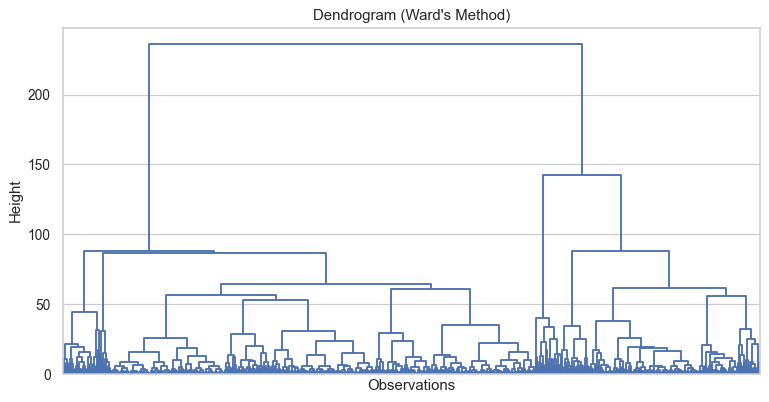

[1 1 1 ... 3 3 3]
1    5582
2     305
3    2350
Name: count, dtype: int64


In [42]:
plt.figure(figsize=(10, 5))                                             # 8
dendrogram(hc, no_labels=True, color_threshold=0)
plt.title("Dendrogram (Ward's Method)"); plt.xlabel("Observations"); plt.ylabel("Height"); plt.show()

clusters = fcluster(hc, t=3, criterion="maxclust")                      # 9
print(clusters)
print(pd.Series(clusters).value_counts().sort_index())                  # 10

# Assignment 9 – Principal Component Analysis (mtcars)

In [43]:
mtcars = sm.datasets.get_rdataset("mtcars").data                        # 1
cars_sel = mtcars[["mpg", "disp", "hp", "drat", "wt", "qsec"]]
display(cars_sel.head()); display(cars_sel.describe())
print(cars_sel.std()); display(cars_sel.corr().round(3))

cars_scaled = (cars_sel - cars_sel.mean()) / cars_sel.std(ddof=1)       # 2
print(cars_scaled.mean().round(4)); print(cars_scaled.std())

,mpg,disp,hp,drat,wt,qsec
rownames,,,,,,
Mazda RX4,21.0,160.0,110,3.90,2.620,16.46
Mazda RX4 Wag,21.0,160.0,110,3.90,2.875,17.02
Datsun 710,22.8,108.0,93,3.85,2.320,18.61
Hornet 4 Drive,21.4,258.0,110,3.08,3.215,19.44
Hornet Sportabout,18.7,360.0,175,3.15,3.440,17.02


,mpg,disp,hp,drat,wt,qsec
count,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000
mean,20.090625,230.721875,146.687500,3.596563,3.217250,17.848750
std,6.026948,123.938694,68.562868,0.534679,0.978457,1.786943
min,10.400000,71.100000,52.000000,2.760000,1.513000,14.500000
25%,15.425000,120.825000,96.500000,3.080000,2.581250,16.892500
50%,19.200000,196.300000,123.000000,3.695000,3.325000,17.710000
75%,22.800000,326.000000,180.000000,3.920000,3.610000,18.900000
max,33.900000,472.000000,335.000000,4.930000,5.424000,22.900000


mpg       6.026948
disp    123.938694
hp       68.562868
drat      0.534679
wt        0.978457
qsec      1.786943
dtype: float64


,mpg,disp,hp,drat,wt,qsec
mpg,1.000,-0.848,-0.776,0.681,-0.868,0.419
disp,-0.848,1.000,0.791,-0.710,0.888,-0.434
hp,-0.776,0.791,1.000,-0.449,0.659,-0.708
drat,0.681,-0.710,-0.449,1.000,-0.712,0.091
wt,-0.868,0.888,0.659,-0.712,1.000,-0.175
qsec,0.419,-0.434,-0.708,0.091,-0.175,1.000


mpg    -0.0
disp    0.0
hp      0.0
drat   -0.0
wt     -0.0
qsec   -0.0
dtype: float64
mpg     1.0
disp    1.0
hp      1.0
drat    1.0
wt      1.0
qsec    1.0
dtype: float64


In [44]:
pca = PCA().fit(cars_scaled)                                            # 3
pcs = [f"PC{i+1}" for i in range(6)]
pca_scores = pca.transform(cars_scaled)

var_explained = pca.explained_variance_ratio_                           # 4
print(pd.DataFrame({"Std Dev": np.sqrt(pca.explained_variance_), "Proportion": var_explained.round(4),
                    "Cumulative": np.cumsum(var_explained).round(4)}, index=pcs))

min_pcs = int(np.argmax(np.cumsum(var_explained) >= 0.80) + 1)          # 5
print("Minimum PCs for >= 80% variance:", min_pcs)

      Std Dev  Proportion  Cumulative
PC1  2.046313      0.6979      0.6979
PC2  1.071500      0.1914      0.8893
PC3  0.577370      0.0556      0.9448
PC4  0.392887      0.0257      0.9705
PC5  0.353265      0.0208      0.9913
PC6  0.227987      0.0087      1.0000
Minimum PCs for >= 80% variance: 2


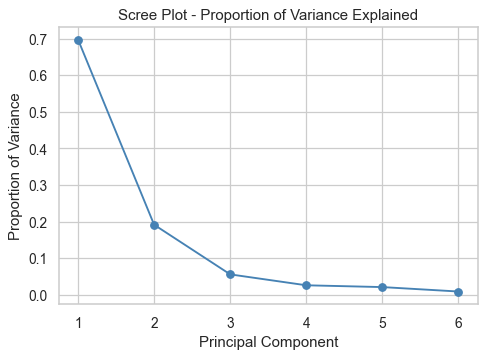

In [45]:
plt.figure(figsize=(6, 4))                                              # 6
plt.plot(range(1, 7), var_explained, marker="o", color="steelblue")
plt.title("Scree Plot - Proportion of Variance Explained"); plt.xlabel("Principal Component"); plt.ylabel("Proportion of Variance")
plt.xticks(range(1, 7)); plt.show()

In [46]:
loadings = pd.DataFrame(pca.components_.T, index=cars_sel.columns, columns=pcs)   # 7
display(loadings.round(3))
print(loadings["PC1"].abs().sort_values(ascending=False)); print(loadings["PC2"].abs().sort_values(ascending=False))

,PC1,PC2,PC3,PC4,PC5,PC6
mpg,0.459,0.059,0.195,0.782,0.111,-0.352
disp,-0.466,-0.061,-0.097,0.600,-0.295,0.568
hp,-0.426,0.361,-0.146,0.123,0.806,-0.048
drat,0.367,0.437,-0.800,0.023,-0.144,0.113
wt,-0.439,-0.300,-0.418,0.104,-0.230,-0.692
qsec,0.253,-0.763,-0.341,0.043,0.422,0.242


disp    0.466035
mpg     0.458684
wt      0.438618
hp      0.425853
drat    0.367096
qsec    0.252832
Name: PC1, dtype: float64
qsec    0.762849
drat    0.436525
hp      0.361476
wt      0.299535
disp    0.060653
mpg     0.058676
Name: PC2, dtype: float64


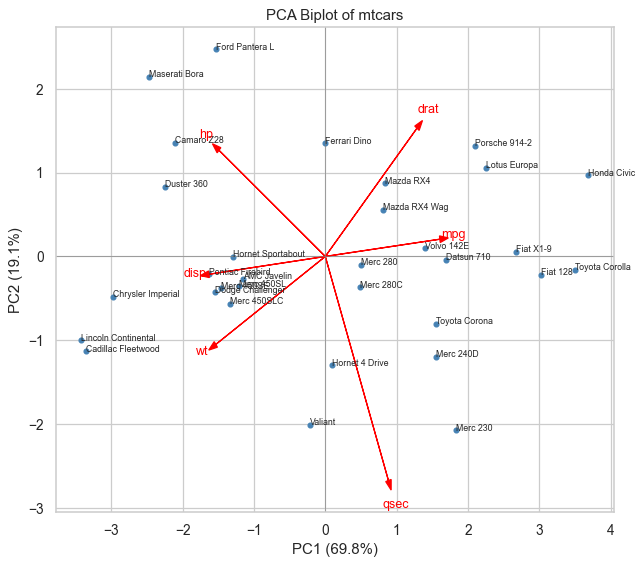

In [47]:
fig, ax = plt.subplots(figsize=(8, 7))                                  # 8
ax.scatter(pca_scores[:, 0], pca_scores[:, 1], color="steelblue", s=15)
for name, (px, py) in zip(cars_sel.index, pca_scores[:, :2]):
    ax.text(px, py, name, fontsize=7)
scale = 3.5
for var, (lx, ly) in zip(cars_sel.columns, loadings[["PC1", "PC2"]].values):
    ax.arrow(0, 0, lx * scale, ly * scale, color="red", head_width=0.08)
    ax.text(lx * scale * 1.12, ly * scale * 1.12, var, color="red", fontsize=10, ha="center")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set(title="PCA Biplot of mtcars", xlabel=f"PC1 ({var_explained[0]*100:.1f}%)", ylabel=f"PC2 ({var_explained[1]*100:.1f}%)")
plt.show()